# 02 · TCGA molecular data

This notebook builds a **patient-level molecular table** for the TCGA patients of one indication that passed image QC in notebook 01, together with a **data dictionary** documenting every variable (source, level, type, coverage). It is the molecular counterpart integrated with the OpenTME features in notebook 03, and covers two kinds of information:

- **Immune activity:** immune infiltration, composition and functional signatures, to relate to where immune cells are in the tissue (tumour core vs invasive margin, tertiary lymphoid structures).
- **Tumour-intrinsic features:** genomic alterations (driver mutations, pathway alterations, arm-level copy number) and tumour states (hypoxia, proliferation), to relate to how the tissue is organised.

**Principles**
- **One row per patient** (`patient` = 12-character TCGA barcode), primary tumours only (sample type `01`), one sample per patient.
- **Derived biological variables only:** consensus scores, deconvolution estimates, pathway calls and signature scores rather than raw matrices.
- **Missingness preserved:** `NaN` = not profiled, strictly distinct from `0` = profiled and not altered.
- **Provenance prefixes:** `clin_`, `abs_`, `thor_`, `cib_`, `mut_`, `path_`, `aneu_`, `hyp_`, `expr_`, `sig_`.

**Data layers**

| # | Layer | Source | Prefix | Download | File in `<data>/raw/tcga/` |
|:-:|---|---|---|---|---|
| 3 | Clinical | [TCGA-CDR](https://gdc.cancer.gov/about-data/publications/PanCan-Clinical-2018) (Liu et al. 2018) | `clin_` | automatic | `TCGA-CDR-SupplementalTableS1.xlsx` |
| 4 | Molecular subtypes | default: TCGA subtype from Thorsson et al. 2018; breast: [Thennavan et al. 2021](https://pmc.ncbi.nlm.nih.gov/articles/PMC9028992/), Data S1 | `clin_` | by hand | `Thennavan_2021_DataS1.xlsx` (breast) |
| 5 | Purity and ploidy | [ABSOLUTE, PanCanAtlas](https://gdc.cancer.gov/about-data/publications/pancanatlas) (Taylor et al. 2018) | `abs_` | automatic | `TCGA_mastercalls.abs_tables_JSedit.fixed.txt` |
| 6 | Immune landscape and CIBERSORT | [Thorsson et al. 2018](https://doi.org/10.1016/j.immuni.2018.03.023), Table S1 | `thor_`, `cib_` | by hand | `thorsson_2018_table_s1.xlsx` |
| 7 | Somatic mutations | [MC3 MAF](https://gdc.cancer.gov/about-data/publications/mc3-2017) | `mut_` | automatic | `mc3.v0.2.8.PUBLIC.maf.gz` |
| 7 | Driver genes | [Bailey et al. 2018](https://doi.org/10.1016/j.cell.2018.02.060), Table S1 | | by hand | `bailey_2018_table_s1.xlsx` |
| 8 | Oncogenic pathways | [Sanchez-Vega et al. 2018](https://doi.org/10.1016/j.cell.2018.03.035), Table S4 | `path_` | by hand | `sanchez_vega_2018_pathways.xlsx` |
| 9 | Arm-level aneuploidy | Taylor et al. 2018, via [cBioPortal](https://github.com/cBioPortal/datahub/tree/master/public) | `aneu_` | automatic | `cbioportal_brca_data_armlevel_cna.txt` |
| 10 | Hypoxia | Bhandari et al. 2019, via [cBioPortal](https://github.com/cBioPortal/datahub/tree/master/public) | `hyp_` | automatic | `cbioportal_brca_data_clinical_supp_hypoxia.txt` |
| 11 | RNA-seq (HiSeqV2) | [UCSC Xena](https://xenabrowser.net/datapages/) | `expr_` | by hand | `TCGA.BRCA.HiSeqV2.gz` |
| 11 | TME signatures | [Bagaev et al. 2021](https://doi.org/10.1016/j.ccell.2021.04.014), Table S1; Messina 2012; MSigDB | `sig_` | by hand | `bagaev_2021_table_s1.xlsx` |

*Automatic* files are downloaded the first time the notebook runs; *by hand* files are supplementary tables to download from the publication and save with the given name. If a file is missing, the notebook stops and says which one. For another indication, `BRCA` / `brca` in some file names becomes its TCGA code.

The *Observations* after each section describe the results of the pilot indication (breast cancer); cells specific to breast (e.g. CDH1 and 16q loss, triple-negative status) run only when those variables exist.

Sources, column names and thresholds are in `configs/analysis.yaml` (section `tcga_molecular`); indication-specific choices (subtype source, histology classes, required arm events, redundancy decisions) are in `configs/indications/<name>.yaml`. Reusable code lives in `src/opentme_tcga/tcga.py`.

**Outputs**
- `<data>/processed/tcga_<opentme>_molecular_master.parquet`: all variables.
- `<data>/processed/tcga_<opentme>_molecular_working.parquet`: without the redundant variables of section 12 (input of notebook 03).
- `<data>/processed/tcga_<opentme>_molecular_dictionary.csv`: data dictionary.
- `<data>/interim/`: filtered mutations and the log2 RNA matrix.
- `figures/<indication>/02_tcga/`: figures.

## 0. Setup

In [1]:
import gseapy as gp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from IPython.display import display
from scipy.stats import spearmanr

from opentme_tcga import tcga
from opentme_tcga.config import ensure_dirs, load_config, source_file
from opentme_tcga.plotting import category_colors
from opentme_tcga.tcga import MolecularTable, format_coverage, primary_one_per_patient, to_patient

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 120)

In [2]:
INDICATION = "breast"          # name of a file in configs/indications/

cfg = load_config(INDICATION)
P = cfg["paths"]
TM = cfg["tcga_molecular"]
TCGA_CODE = cfg["indication"]["tcga_code"]          # e.g. BRCA
TCGA_PROJECT = cfg["indication"]["tcga_project"]    # e.g. TCGA-BRCA
NA = TM["na_strings"]
SAMPLE_TYPES = tuple(TM["sample_types"])
SUB = TM["subtypes"]
SUBTYPE_COL, SUBTYPE_LABEL = SUB["column"], SUB["label"]

ensure_dirs(cfg, ("interim", "processed", "results", "raw_tcga"))
OUT_DIR = P["results"] / "02_tcga"          # tables
FIGS = P["figures"] / "02_tcga"             # figures
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)


def src(name: str) -> dict:
    # Source spec with resolved path; downloads it if a URL is configured and the file is missing.
    spec = source_file(cfg, name)
    if "url" in spec:
        tcga.download(spec["url"], spec["path"])
    return {**spec, "path": tcga.require_file(spec["path"], spec.get("reference", ""))}


def primary(df, barcode_col, name):
    out, log = primary_one_per_patient(df, barcode_col, SAMPLE_TYPES)
    print(f"[{name}] sample types: {log['sample_types']}")
    print(f"[{name}] {log['n_patients']} patients -> {log['n_primary_patients']} with a primary tumour sample "
          f"({log['n_extra_samples']} extra primary samples dropped)")
    return out


print(f"Indication: {INDICATION} ({TCGA_PROJECT})")
print(f"Raw TCGA files: {P['raw_tcga']}")

Indication: breast (TCGA-BRCA)
Raw TCGA files: /Users/Admin/Desktop/GitHub/opentme-tcga-integration/data/raw/tcga


## 1. Reference cohort: OpenTME patients

The patients of the OpenTME master table (notebook 01, after image QC) define the cohort and the index of the molecular table.

In [3]:
opentme_ids = pd.read_parquet(P["opentme_patients"], columns=["TCGA_CASE_ID"])["TCGA_CASE_ID"]
patients = pd.Index(sorted(to_patient(opentme_ids).unique()), name="patient")
print(f"OpenTME patients after image QC: {len(patients)}")

OpenTME patients after image QC: 1030


## 3. Clinical data (TCGA-CDR)

**Source:** Liu et al., *Cell* 2018 ([TCGA-CDR](https://gdc.cancer.gov/about-data/publications/PanCan-Clinical-2018)), downloaded automatically from the GDC API.

### 3.1 Load and define the cohort

Patients flagged as **redacted** by TCGA are excluded from the cohort. Male patients are kept, with an explicit indicator (`clin_sex`).

In [4]:
spec = src("cdr")
cdr = pd.read_excel(spec["path"], sheet_name=spec["sheet"], na_values=NA)
cdr = cdr.drop(columns=[c for c in cdr.columns if str(c).startswith("Unnamed")])
cdr_tcga = cdr[cdr["type"] == TCGA_CODE].copy()
print(f"All cancers: {cdr.shape} | {TCGA_CODE}: {cdr_tcga.shape}, "
      f"{cdr_tcga['bcr_patient_barcode'].nunique()} unique patients")

pd.DataFrame({
    "n_missing": cdr_tcga.isna().sum(),
    "pct_missing": (100 * cdr_tcga.isna().mean()).round(1),
    "n_unique": cdr_tcga.nunique(),
})

All cancers: (11160, 33) | BRCA: (1097, 33), 1097 unique patients


,n_missing,pct_missing,n_unique
bcr_patient_barcode,0,0.0,1097
type,0,0.0,1
age_at_initial_pathologic_diagnosis,1,0.1,65
gender,0,0.0,2
race,95,8.7,4
ajcc_pathologic_tumor_stage,11,1.0,12
clinical_stage,1097,100.0,0
histological_type,1,0.1,8
histological_grade,1097,100.0,0
initial_pathologic_dx_year,3,0.3,26


In [5]:
print("Sex:", cdr_tcga["gender"].value_counts(dropna=False).to_dict())
redacted = tcga.redacted_patients(cdr_tcga)
print(f"Redacted: {len(redacted)} in {TCGA_CODE} | {patients.isin(redacted).sum()} in the OpenTME cohort")

patients = patients.difference(redacted)
table = MolecularTable(patients)
print(f"Cohort: {len(patients)} patients")
print(format_coverage("TCGA-CDR", tcga.coverage(to_patient(cdr_tcga["bcr_patient_barcode"]), patients)))

Sex: {'FEMALE': 1085, 'MALE': 12}
Redacted: 5 in BRCA | 5 in the OpenTME cohort
Cohort: 1025 patients
[TCGA-CDR] cohort patients with data: 1025 / 1025 (100.0 %)


### 3.2 Select and recode

- **Histology (`clin_histology`):** histological types grouped into a few classes (`histology_map` in the indication file; anything else is `other`).
- **Stage (`clin_stage_simple`):** AJCC pathologic stage collapsed to I–IV; `Stage X` and unexpected values are `NaN`.
- **Hospital (`clin_tss`):** tissue source site, barcode characters 6–7 (batch effect; used to split train and test sets in notebook 07).
- **Age, sex, survival endpoints (OS, PFI), margin and menopause status** as provided.

In [6]:
cl = TM["clinical"]
clinical = tcga.clinical_block(cdr_tcga, cl["columns"], cl["numeric"], cl.get("histology_map"))
table.add(clinical, source="TCGA-CDR (Liu 2018)", level="main", descriptions=cl.get("descriptions"))
molecular = table.data

for col in ["clin_sex", "clin_histology", "clin_stage_simple"]:
    print(f"--- {col} ---")
    print(molecular[col].value_counts(dropna=False).to_string(), "\n")
molecular["clin_age"].describe()

--- clin_sex ---
clin_sex
FEMALE    1013
MALE        12 

--- clin_histology ---
clin_histology
ductal     737
lobular    184
other       76
mixed       27
NaN          1 

--- clin_stage_simple ---
clin_stage_simple
II     585
III    231
I      169
NaN     23
IV      17 



count    1024.000000
mean       58.456055
std        13.273130
min        26.000000
25%        49.000000
50%        58.000000
75%        68.000000
max        90.000000
Name: clin_age, dtype: float64

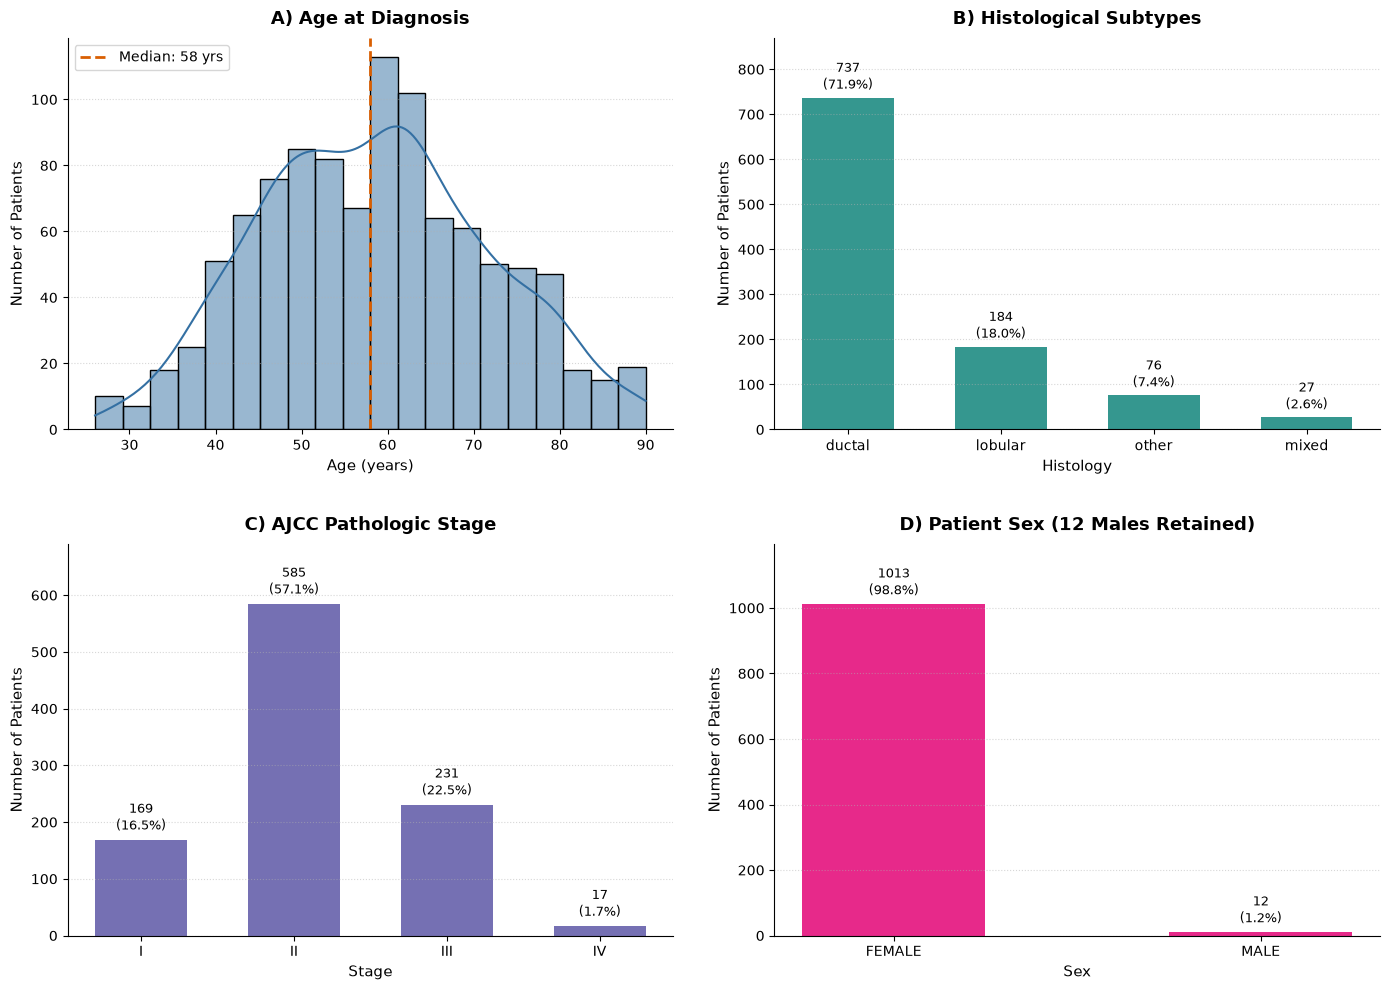

In [7]:
# Clinical and demographic distributions

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) Panel A: Age at diagnosis (Histogram + KDE)
ax = axes[0, 0]
sns.histplot(molecular["clin_age"].dropna(), kde=True, color="#3470a3", bins=20, ax=ax)
median_age = molecular["clin_age"].median()
ax.axvline(median_age, color="#d95f02", linestyle="--", linewidth=2, label=f"Median: {median_age:.0f} yrs")
ax.set_title("A) Age at Diagnosis", fontsize=13, fontweight="bold", pad=10)
ax.set_xlabel("Age (years)", fontsize=11)
ax.set_ylabel("Number of Patients", fontsize=11)
ax.legend(frameon=True, facecolor="white", loc="upper left")

# 2) Panel B: Simplified Histology
ax = axes[0, 1]
hist_counts = molecular["clin_histology"].value_counts(dropna=True)
bars = ax.bar(hist_counts.index, hist_counts.values, color="#35978f", width=0.6)
ax.set_title("B) Histological Subtypes", fontsize=13, fontweight="bold", pad=10)
ax.set_xlabel("Histology", fontsize=11)
ax.set_ylabel("Number of Patients", fontsize=11)
for bar in bars:
    yval = bar.get_height()
    pct = 100 * yval / len(molecular)
    ax.text(bar.get_x() + bar.get_width()/2, yval + 10, f"{yval}\n({pct:.1f}%)", 
            ha="center", va="bottom", fontsize=9.5)
ax.set_ylim(0, max(hist_counts.values) * 1.18)

# 3) Panel C: Pathologic Stage (Collapsed I–IV)
ax = axes[1, 0]
stage_order = ["I", "II", "III", "IV"]
stage_counts = molecular["clin_stage_simple"].value_counts().reindex(stage_order).fillna(0)
bars = ax.bar(stage_counts.index, stage_counts.values, color="#7570b3", width=0.6)
ax.set_title("C) AJCC Pathologic Stage", fontsize=13, fontweight="bold", pad=10)
ax.set_xlabel("Stage", fontsize=11)
ax.set_ylabel("Number of Patients", fontsize=11)
for bar in bars:
    yval = int(bar.get_height())
    pct = 100 * yval / len(molecular)
    ax.text(bar.get_x() + bar.get_width()/2, yval + 10, f"{yval}\n({pct:.1f}%)", 
            ha="center", va="bottom", fontsize=9.5)
ax.set_ylim(0, max(stage_counts.values) * 1.18)

# 4) Panel D: Sex Distribution
ax = axes[1, 1]
sex_counts = molecular["clin_sex"].value_counts(dropna=True)
bars = ax.bar(sex_counts.index, sex_counts.values, color="#e7298a", width=0.5)
ax.set_title("D) Patient Sex (12 Males Retained)", fontsize=13, fontweight="bold", pad=10)
ax.set_xlabel("Sex", fontsize=11)
ax.set_ylabel("Number of Patients", fontsize=11)
for bar in bars:
    yval = bar.get_height()
    pct = 100 * yval / len(molecular)
    ax.text(bar.get_x() + bar.get_width()/2, yval + 15, f"{yval}\n({pct:.1f}%)", 
            ha="center", va="bottom", fontsize=9.5)
ax.set_ylim(0, max(sex_counts.values) * 1.18)

# Polish aesthetics
for ax_flat in axes.flat:
    ax_flat.spines[["top", "right"]].set_visible(False)
    ax_flat.grid(axis="y", linestyle=":", alpha=0.5)

plt.tight_layout(h_pad=3.0, w_pad=2.5)
plt.show()

## 4. Molecular subtypes

The subtype groups the figures of this notebook and is a key covariate downstream (`subtypes` in the configuration). By default it is the **TCGA molecular subtype** of Thorsson et al. 2018 (column `TCGA Subtype`), available for every cancer type; an indication can use a curated source instead.

**Breast** uses [Thennavan et al., *Cell Genomics* 2021](https://pmc.ncbi.nlm.nih.gov/articles/PMC9028992/), Data S1 (download by hand): curated annotations for the TCGA breast cohort by the group that developed PAM50.
- **Triple negative** (ER−, PR−, HER2− by clinical IHC). In triple-negative tumours, [Hammerl et al., *Nat Commun* 2021](https://doi.org/10.1038/s41467-021-25962-0) described the spatial immune phenotypes studied here.
- **PAM50 subtype** from the RNA expression of 50 genes ([Parker et al., *J Clin Oncol* 2009](https://doi.org/10.1200/JCO.2008.18.1370)): *Luminal A* (ER+, low proliferation), *Luminal B* (ER+, higher proliferation), *HER2-enriched*, *Basal-like* (mostly triple negative, highly proliferative, frequent TP53 mutations, more immune infiltration) and *Normal-like* (resembles normal breast, often low purity). The few *claudin-low* tumours are pooled into Basal.

The subtype shapes both tissue architecture and molecular profile, so it is a key **covariate**; for breast, predicting PAM50 from H&E is published, so it is also a **benchmark** for the models.

In [8]:
if SUB["source"] == "file":
    spec = src("subtypes")
    raw = pd.read_excel(spec["path"], sheet_name=spec["sheet"], na_values=NA)
    sub = primary(raw, spec["barcode_column"], "Subtypes").set_index("patient")
    subtypes = tcga.recode_columns(sub, spec["columns"])
    source = spec["reference"]
    descriptions = {k: v.get("description", "") for k, v in spec["columns"].items()}
else:
    th = TM["thorsson"]
    thorsson = pd.read_excel(src("thorsson")["path"], sheet_name=TM["sources"]["thorsson"]["sheet"], na_values=NA)
    thorsson = thorsson[thorsson[th["study_column"]] == TCGA_CODE]
    subtypes = tcga.thorsson_subtype(thorsson, th["id_column"], SUB["thorsson_column"], TCGA_CODE).to_frame(SUBTYPE_COL)
    source = "Thorsson et al. 2018 (Table S1, TCGA Subtype)"
    descriptions = {SUBTYPE_COL: f"TCGA molecular subtype of {TCGA_CODE} (Thorsson Table S1)"}

print(format_coverage("Subtypes", tcga.coverage(subtypes.index, patients)))
table.add(subtypes, source=source, level="main", descriptions=descriptions)
molecular = table.data

present = molecular[SUBTYPE_COL].dropna().unique()
SUBTYPE_ORDER = [s for s in SUB.get("order") or molecular[SUBTYPE_COL].value_counts().index if s in present]
SUBTYPE_COLORS = category_colors(SUBTYPE_ORDER, SUB.get("colors"))
print(f"{SUBTYPE_LABEL} ({SUBTYPE_COL}):")
molecular[SUBTYPE_COL].value_counts(dropna=False).to_frame("n_patients").T

[Subtypes] sample types: {'01': 1095, '11': 97, '06': 6}
[Subtypes] 1095 patients -> 1095 with a primary tumour sample (0 extra primary samples dropped)
[Subtypes] cohort patients with data: 1023 / 1025 (99.8 %); first missing: ['TCGA-AC-A5EI', 'TCGA-C8-A9FZ']
PAM50 subtype (clin_pam50):


clin_pam50,LumA,LumB,Basal,HER2E,normal-like,NaN
n_patients,521,214,176,77,35,2


In [9]:
# Breast: subtype vs triple-negative status
if "clin_tnbc" in molecular:
    display(pd.crosstab(molecular[SUBTYPE_COL], molecular["clin_tnbc"], margins=True, dropna=False))

clin_tnbc,False,True,NaN,All
clin_pam50,,,,
Basal,34,133,9,176
HER2E,59,14,4,77
LumA,492,7,22,521
LumB,201,1,12,214
normal-like,22,10,3,35
NaN,0,0,2,2
All,808,165,52,1025


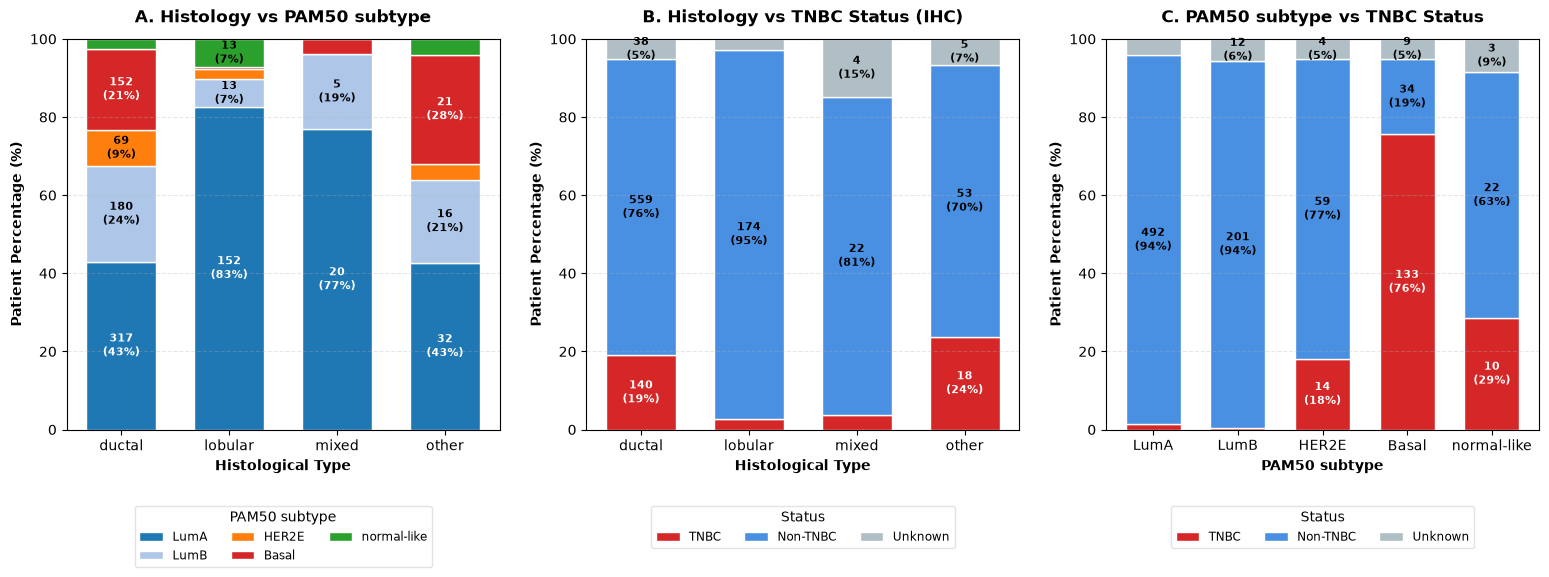

In [10]:
if {'clin_tnbc', 'clin_histology'} <= set(molecular):
    # =============================================================================
    # Diagnostic Visualization: Histology vs subtype vs TNBC Status
    # =============================================================================

    tnbc_col = "clin_tnbc"

    # Clean string mapping for TNBC (supports boolean True/False and pd.NA)
    tnbc_series = molecular[tnbc_col].map({True: "TNBC", False: "Non-TNBC", 1: "TNBC", 0: "Non-TNBC"}).fillna("Unknown")

    # 2. Curated color palettes

    TNBC_COLORS = {
        "TNBC": "#d62728",        # Crimson red
        "Non-TNBC": "#4a90e2",    # Slate blue
        "Unknown": "#b0bec5"      # Light gray
    }

    # Helper function to plot stacked percentages with bottom legends
    def plot_stacked_composition(ax, ct_counts, color_map, title, xlabel, legend_title, ncol=3):
        ct_pct = ct_counts.div(ct_counts.sum(axis=1), axis=0) * 100
        bottom = pd.Series(0.0, index=ct_pct.index)

        for col in ct_pct.columns:
            values = ct_pct[col]
            counts = ct_counts[col]
            color = color_map.get(col, "#cccccc")

            ax.bar(ct_pct.index, values, bottom=bottom, label=str(col), color=color, edgecolor="white", width=0.65)

            for i, (val, cnt) in enumerate(zip(values, counts)):
                if val >= 5.0:  # Only annotate bars with visible width
                    txt_color = "white" if col in ["LumA", "Basal", "TNBC"] else "black"
                    ax.text(i, bottom.iloc[i] + val / 2, f"{int(cnt)}\n({val:.0f}%)", 
                            ha="center", va="center", color=txt_color,
                            fontsize=8, fontweight="bold")
            bottom += values

        ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
        ax.set_xlabel(xlabel, fontsize=10, fontweight="bold")
        ax.set_ylabel("Patient Percentage (%)", fontsize=10, fontweight="bold")
        ax.set_ylim(0, 100)
        ax.grid(axis="y", linestyle="--", alpha=0.3)

        # Legend placed strictly BELOW the axis to avoid obscuring any data
        ax.legend(title=legend_title, loc="upper center", bbox_to_anchor=(0.5, -0.18), 
                  ncol=ncol, frameon=True, facecolor="white", edgecolor="#dcdcdc", fontsize=8.5)

    # 3. Create 3-panel publication figure
    fig, axes = plt.subplots(1, 3, figsize=(19, 6.2))

    # Order categories
    hist_order = [h for h in ["ductal", "lobular", "mixed", "other"] if h in molecular["clin_histology"].dropna().unique()]
    pam_order = [s for s in SUBTYPE_ORDER if s in molecular[SUBTYPE_COL].unique()]
    tnbc_order = [t for t in ["TNBC", "Non-TNBC", "Unknown"] if t in tnbc_series.unique()]

    # Panel A: Histology vs subtype (ncol=3 for a clean 2-row layout below)
    ct_hist_pam = pd.crosstab(molecular["clin_histology"], molecular[SUBTYPE_COL]).reindex(index=hist_order, columns=pam_order).fillna(0)
    plot_stacked_composition(axes[0], ct_hist_pam, SUBTYPE_COLORS, 
                             f"A. Histology vs {SUBTYPE_LABEL}", "Histological Type", f"{SUBTYPE_LABEL}", ncol=3)

    # Panel B: Histology vs TNBC (ncol=3 for 1 row below)
    ct_hist_tnbc = pd.crosstab(molecular["clin_histology"], tnbc_series).reindex(index=hist_order, columns=tnbc_order).fillna(0)
    plot_stacked_composition(axes[1], ct_hist_tnbc, TNBC_COLORS, 
                             "B. Histology vs TNBC Status (IHC)", "Histological Type", "Status", ncol=3)

    # Panel C: subtype vs TNBC (ncol=3 for 1 row below)
    ct_pam_tnbc = pd.crosstab(molecular[SUBTYPE_COL], tnbc_series).reindex(index=pam_order, columns=tnbc_order).fillna(0)
    plot_stacked_composition(axes[2], ct_pam_tnbc, TNBC_COLORS, 
                             f"C. {SUBTYPE_LABEL} vs TNBC Status", f"{SUBTYPE_LABEL}", "Status", ncol=3)

    # Leave space at bottom for external legends
    plt.subplots_adjust(bottom=0.25)
    plt.show()

**Observations (breast)**
- Ductal carcinoma spans all PAM50 subtypes, while lobular carcinoma is almost exclusively Luminal A/B: histology and PAM50 carry complementary information.
- Triple-negative tumours are mostly ductal and mostly Basal-like; about three quarters of Basal-like tumours are TNBC by IHC, and Luminal tumours are almost never TNBC.
- Some HER2-enriched tumours are TNBC by IHC (HER2 pathway active without protein overexpression).

## 5. Purity and ploidy (ABSOLUTE)

**Source:** PanCanAtlas ABSOLUTE calls ([Carter et al., *Nat Biotechnol* 2012](https://doi.org/10.1038/nbt.2203); [Taylor et al., *Cancer Cell* 2018](https://doi.org/10.1016/j.ccell.2018.03.007)). ABSOLUTE estimates from DNA the fraction of tumour cells (purity), the average number of genome copies (ploidy) and whole-genome doublings.

Bulk molecular measurements are diluted by non-tumour cells, so `abs_purity` is a key covariate to separate tumour-intrinsic biology from tissue composition. Only confident solutions (`call status == "called"`) are kept; the others stay `NaN`. The `sample` column is used as barcode because it includes the vial.

In [11]:
spec = src("absolute")
absolute = pd.read_csv(spec["path"], sep="\t")
ab = TM["absolute"]
abs_tcga = absolute[to_patient(absolute["sample"]).isin(set(to_patient(cdr_tcga["bcr_patient_barcode"])))]
print(f"{TCGA_CODE} samples: {len(abs_tcga)}")
print(abs_tcga["call status"].value_counts(dropna=False).to_string())

abs_called = abs_tcga[abs_tcga["call status"] == ab["call_status"]]
purity = primary(abs_called, "sample", "ABSOLUTE").set_index("patient")[list(ab["columns"])].rename(columns=ab["columns"])
print(format_coverage("ABSOLUTE", tcga.coverage(purity.index, patients)))
table.add(purity, source="ABSOLUTE (PanCanAtlas)", level="main", descriptions={
    "abs_purity": "Tumour purity from DNA (fraction of tumour cells), ABSOLUTE",
    "abs_ploidy": "Average tumour ploidy (genome copies; normal = 2), ABSOLUTE",
    "abs_genome_doublings": "Number of whole-genome doublings, ABSOLUTE",
})
molecular = table.data
display(molecular[["abs_purity", "abs_ploidy"]].describe())
# Breast sanity check: Normal-like tumours should have the lowest purity
molecular.groupby(SUBTYPE_COL)["abs_purity"].median().sort_values()

BRCA samples: 1050
call status
called    1030
NaN         20
[ABSOLUTE] sample types: {'01': 1023, '06': 7}
[ABSOLUTE] 1023 patients -> 1023 with a primary tumour sample (0 extra primary samples dropped)
[ABSOLUTE] cohort patients with data: 957 / 1025 (93.4 %); first missing: ['TCGA-A2-A0CY', 'TCGA-A2-A0CZ', 'TCGA-A2-A0EP', 'TCGA-A2-A1G6', 'TCGA-A2-A25B']


,abs_purity,abs_ploidy
count,957.000000,957.000000
mean,0.586071,2.645841
std,0.184865,0.813408
min,0.090000,1.270000
25%,0.450000,2.000000
50%,0.590000,2.180000
75%,0.730000,3.340000
max,1.000000,5.830000


clin_pam50
normal-like    0.360
HER2E          0.500
Basal          0.545
LumA           0.590
LumB           0.680
Name: abs_purity, dtype: float64

Patients without purity: absent from the ABSOLUTE file, or present without a confident solution?

In [12]:
no_purity = molecular.index[molecular["abs_purity"].isna()]
in_file = no_purity[no_purity.isin(set(to_patient(absolute["sample"])))]
print(f"Without purity: {len(no_purity)} | in the ABSOLUTE file without a confident call: {len(in_file)}")
molecular.loc[in_file, SUBTYPE_COL].value_counts()

Without purity: 68 | in the ABSOLUTE file without a confident call: 18


clin_pam50
normal-like    5
Basal          5
LumA           4
LumB           3
HER2E          1
Name: count, dtype: int64

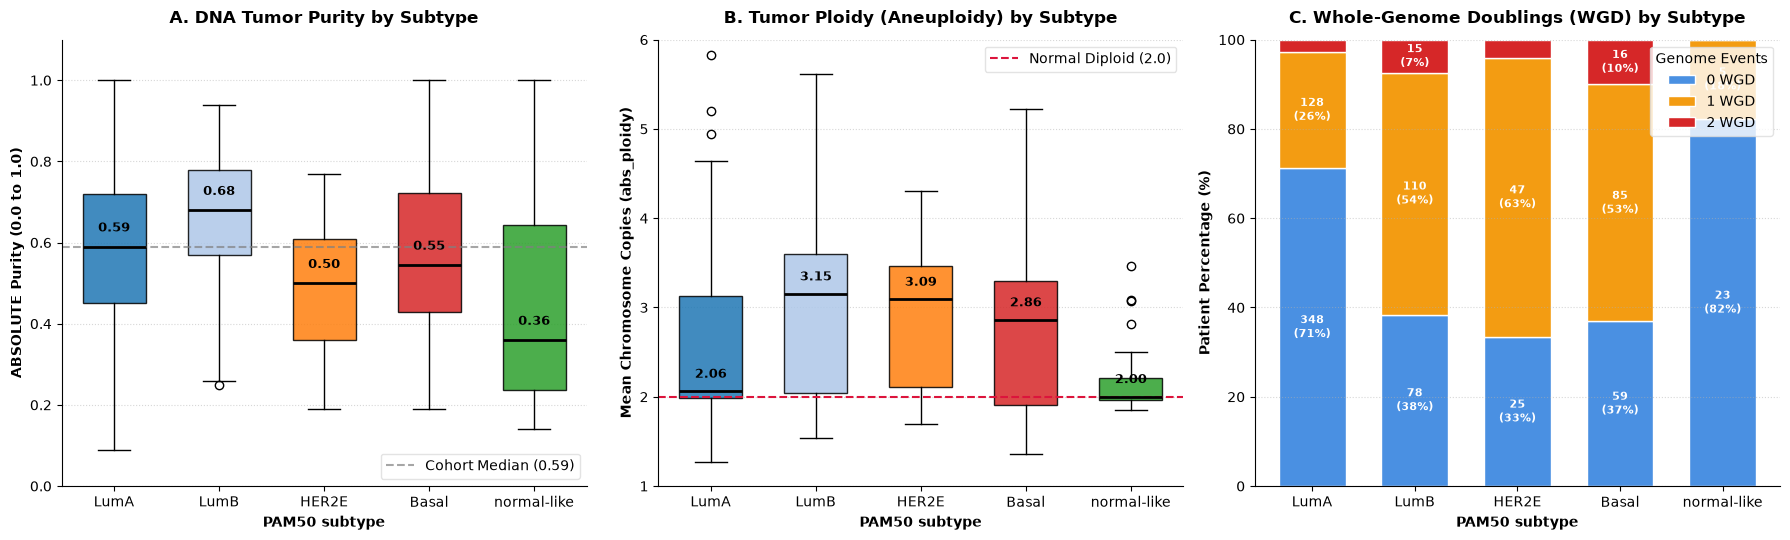

In [13]:
# =============================================================================
# Diagnostic Visualization: Tumor Purity, Ploidy & WGD across subtype Subtypes
# =============================================================================

# Filter patients with valid ABSOLUTE calls and subtype subtype
df_plot = molecular.dropna(subset=["abs_purity", "abs_ploidy", SUBTYPE_COL]).copy()

WGD_COLORS = {
    0.0: "#4a90e2",   # Slate blue (no doubling)
    1.0: "#f39c12",   # Amber / Orange (1 WGD)
    2.0: "#d62728"    # Crimson red (2 WGD)
}

subtype_order = [s for s in SUBTYPE_ORDER if s in df_plot[SUBTYPE_COL].unique()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# -----------------------------------------------------------------------------
# Panel A: Tumor Purity across subtype Subtypes
# -----------------------------------------------------------------------------
ax1 = axes[0]
purity_data = [df_plot[df_plot[SUBTYPE_COL] == s]["abs_purity"].values for s in subtype_order]

bp1 = ax1.boxplot(purity_data, tick_labels=subtype_order, patch_artist=True, widths=0.6,
                  medianprops=dict(color="black", linewidth=2.0))

for patch, s in zip(bp1["boxes"], subtype_order):
    patch.set_facecolor(SUBTYPE_COLORS.get(s, "#cccccc"))
    patch.set_alpha(0.85)

# Cohort median reference line
cohort_purity_med = df_plot["abs_purity"].median()
ax1.axhline(cohort_purity_med, color="gray", linestyle="--", alpha=0.7, 
            label=f"Cohort Median ({cohort_purity_med:.2f})")

# Annotate median values above each boxplot
for i, s in enumerate(subtype_order):
    med_val = np.median(df_plot[df_plot[SUBTYPE_COL] == s]["abs_purity"])
    ax1.text(i + 1, med_val + 0.03, f"{med_val:.2f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax1.set_title("A. DNA Tumor Purity by Subtype", fontsize=12, fontweight="bold", pad=12)
ax1.set_xlabel(f"{SUBTYPE_LABEL}", fontsize=10, fontweight="bold")
ax1.set_ylabel("ABSOLUTE Purity (0.0 to 1.0)", fontsize=10, fontweight="bold")
ax1.set_ylim(0, 1.1)
ax1.grid(axis="y", linestyle=":", alpha=0.5)
ax1.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#dcdcdc")

# -----------------------------------------------------------------------------
# Panel B: Tumor Ploidy (Aneuploidy) across subtype Subtypes
# -----------------------------------------------------------------------------
ax2 = axes[1]
ploidy_data = [df_plot[df_plot[SUBTYPE_COL] == s]["abs_ploidy"].values for s in subtype_order]

bp2 = ax2.boxplot(ploidy_data, tick_labels=subtype_order, patch_artist=True, widths=0.6,
                  medianprops=dict(color="black", linewidth=2.0))

for patch, s in zip(bp2["boxes"], subtype_order):
    patch.set_facecolor(SUBTYPE_COLORS.get(s, "#cccccc"))
    patch.set_alpha(0.85)

# Diploid baseline reference line
ax2.axhline(2.0, color="crimson", linestyle="--", linewidth=1.5, label="Normal Diploid (2.0)")

# Annotate median values
for i, s in enumerate(subtype_order):
    med_val = np.median(df_plot[df_plot[SUBTYPE_COL] == s]["abs_ploidy"])
    ax2.text(i + 1, med_val + 0.12, f"{med_val:.2f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax2.set_title("B. Tumor Ploidy (Aneuploidy) by Subtype", fontsize=12, fontweight="bold", pad=12)
ax2.set_xlabel(f"{SUBTYPE_LABEL}", fontsize=10, fontweight="bold")
ax2.set_ylabel("Mean Chromosome Copies (abs_ploidy)", fontsize=10, fontweight="bold")
ax2.set_ylim(1.0, 6.0)
ax2.grid(axis="y", linestyle=":", alpha=0.5)
ax2.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#dcdcdc")

# -----------------------------------------------------------------------------
# Panel C: Whole-Genome Doubling (WGD) Events by Subtype
# -----------------------------------------------------------------------------
ax3 = axes[2]
ct_wgd = pd.crosstab(df_plot[SUBTYPE_COL], df_plot["abs_genome_doublings"]).reindex(subtype_order).fillna(0)
ct_wgd_pct = ct_wgd.div(ct_wgd.sum(axis=1), axis=0) * 100

bottom3 = pd.Series(0.0, index=ct_wgd_pct.index)
for wgd in [0.0, 1.0, 2.0]:
    if wgd in ct_wgd_pct.columns:
        vals = ct_wgd_pct[wgd]
        cnts = ct_wgd[wgd]
        color = WGD_COLORS.get(wgd, "#cccccc")
        wgd_label = f"{int(wgd)} WGD"
        
        ax3.bar(ct_wgd_pct.index, vals, bottom=bottom3, label=wgd_label, 
                color=color, edgecolor="white", width=0.65)
        
        for i, (val, cnt) in enumerate(zip(vals, cnts)):
            if val >= 6.0:
                ax3.text(i, bottom3.iloc[i] + val / 2, f"{int(cnt)}\n({val:.0f}%)", 
                         ha="center", va="center", color="white", fontsize=8, fontweight="bold")
        bottom3 += vals

ax3.set_title("C. Whole-Genome Doublings (WGD) by Subtype", fontsize=12, fontweight="bold", pad=12)
ax3.set_xlabel(f"{SUBTYPE_LABEL}", fontsize=10, fontweight="bold")
ax3.set_ylabel("Patient Percentage (%)", fontsize=10, fontweight="bold")
ax3.set_ylim(0, 100)
ax3.grid(axis="y", linestyle=":", alpha=0.5)
ax3.legend(title="Genome Events", loc="upper right", frameon=True, facecolor="white", edgecolor="#dcdcdc")

# Polish layout
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Observations (breast)**
- Normal-like tumours have the lowest purity (much non-tumour tissue); patients without a confident ABSOLUTE call are enriched in Normal-like, so purity is not missing completely at random.
- Luminal A tumours are mostly near-diploid without genome doubling; Luminal B, HER2-enriched and Basal-like tumours are highly aneuploid, with frequent whole-genome doubling.
- Analyses can be reported with and without adjustment for purity (adjusting may also remove real compositional biology).

## 6. Immune landscape (Thorsson et al., 2018)

**Source:** [Thorsson et al., *Immunity* 2018](https://doi.org/10.1016/j.immuni.2018.03.023), Table S1 (download by hand). Pan-cancer immune characterisation of TCGA tumours from bulk RNA, DNA methylation, mutations and copy number; one row per patient.

| Subtype | Name | Main feature |
|---|---|---|
| C1 | Wound healing | Angiogenesis, high proliferation |
| C2 | IFN-γ dominant | Strong cytotoxic T-cell response |
| C3 | Inflammatory | Balanced immune response; best prognosis |
| C4 | Lymphocyte depleted | Macrophage-rich, few lymphocytes |
| C5 | Immunologically quiet | Almost no immune cells (mostly gliomas) |
| C6 | TGF-β dominant | High TGF-β and stroma; worst prognosis |

It is the reference molecular readout of immune activity: bulk RNA estimates cell proportions without spatial context, while OpenTME measures where the cells are.

- **Thorsson variables (main):** immune subtype, leukocyte fraction (DNA methylation), TIL fraction from H&E (Saltz 2018), five signatures (TGF-β, IFN-γ, lymphocyte infiltration, macrophage regulation, proliferation), TMB, neoantigens, aneuploidy score, heterogeneity, HRD and BCR richness.
- **CIBERSORT (22 cell types):** proportions **within leukocytes** (they sum to 1), i.e. composition of the infiltrate, not amount. Main: CD8 T cells, Tregs, M2 macrophages (type of response and brakes) and naive and memory B cells, plasma cells, follicular helper T cells (TLS). The rest are exploratory.
- **Own sums (exploratory):** lymphocytes (T + B + NK) and macrophages (M0 + M1 + M2), for description only.

In [14]:
spec = src("thorsson")
th = TM["thorsson"]
thorsson = pd.read_excel(spec["path"], sheet_name=spec["sheet"], na_values=NA)
thor_tcga = thorsson[thorsson[th["study_column"]] == TCGA_CODE].assign(patient=lambda d: to_patient(d[th["id_column"]]).to_numpy())
assert thor_tcga["patient"].is_unique, "Duplicated patients in Thorsson table"
thor_tcga = thor_tcga.set_index("patient")
print(format_coverage("Thorsson", tcga.coverage(thor_tcga.index, patients)))

cib = {c: "cib_" + tcga.snake(c) for c in th["cibersort_main"] + th["cibersort_exploratory"]}
thor = thor_tcga[list(th["columns"]) + list(cib)].rename(columns={**th["columns"], **cib})
desc = {new: f"CIBERSORT: {old} (proportion within leukocytes)" for old, new in cib.items()}
desc.update({new: f"Thorsson 2018: {old}" for old, new in th["columns"].items()})

main_cols = list(th["columns"].values()) + [cib[c] for c in th["cibersort_main"]]
table.add(thor[main_cols], source="Thorsson et al. 2018 (Table S1)", level="main", descriptions=desc)
table.add(thor[[cib[c] for c in th["cibersort_exploratory"]]], source="Thorsson et al. 2018 (Table S1)",
          level="exploratory", descriptions=desc)

sums = pd.DataFrame({name: table.data[cols].sum(axis=1, min_count=1) for name, cols in th["sums"].items()})
table.add(sums, source="Derived from CIBERSORT", level="exploratory",
          descriptions={n: "Own sum of CIBERSORT proportions; redundant with its components" for n in sums})
molecular = table.data
molecular.filter(regex="^(thor_|cib_)").notna().sum().to_frame("n_with_data").T

[Thorsson] cohort patients with data: 1015 / 1025 (99.0 %); first missing: ['TCGA-A8-A084', 'TCGA-A8-A08F', 'TCGA-A8-A08S', 'TCGA-A8-A09E', 'TCGA-A8-A09K']


,thor_immune_subtype,thor_leukocyte_fraction,thor_til_fraction_he,thor_tgfb_response,thor_ifng_response,thor_lymphocyte_infiltration,thor_macrophage_regulation,thor_proliferation,thor_tmb,thor_snv_neoantigens,thor_aneuploidy_score,thor_heterogeneity,thor_hrd,thor_bcr_richness,cib_t_cells_cd8,cib_t_cells_regulatory_tregs,cib_macrophages_m2,cib_b_cells_naive,cib_b_cells_memory,cib_plasma_cells,cib_t_cells_follicular_helper,cib_t_cells_cd4_naive,cib_t_cells_cd4_memory_resting,cib_t_cells_cd4_memory_activated,cib_t_cells_gamma_delta,cib_nk_cells_resting,cib_nk_cells_activated,cib_monocytes,cib_macrophages_m0,cib_macrophages_m1,cib_dendritic_cells_resting,cib_dendritic_cells_activated,cib_mast_cells_resting,cib_mast_cells_activated,cib_eosinophils,cib_neutrophils,cib_lymphocytes,cib_macrophages
n_with_data,1013,998,916,1013,1013,1013,1013,1013,995,932,974,956,974,738,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013,1013


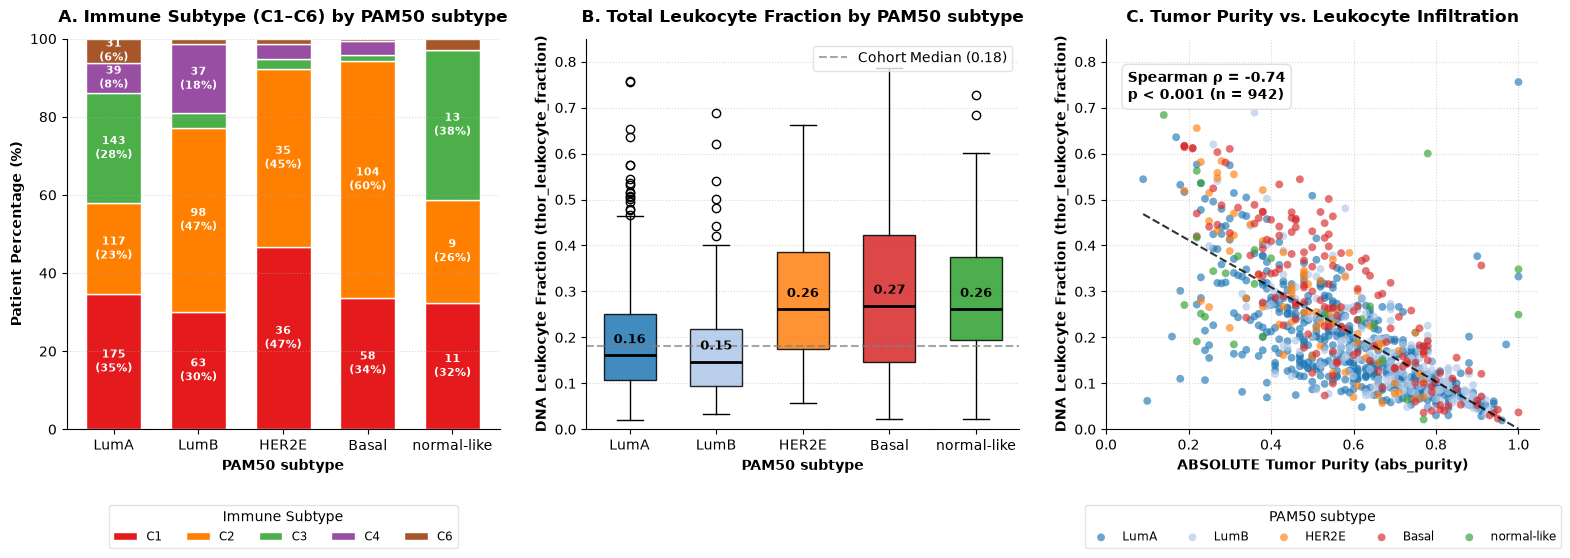

In [15]:
# =============================================================================
# Diagnostic Visualization: Immune Subtypes, Leukocyte Fraction & Coherence
# =============================================================================

# Filter patients with valid immune subtype, leukocyte fraction, and subtype
df_plot = molecular.dropna(subset=[SUBTYPE_COL, "thor_immune_subtype", "thor_leukocyte_fraction"]).copy()

IMMUNE_COLORS = {
    "C1": "#e41a1c", "C2": "#ff7f00", "C3": "#4daf4a", "C4": "#984ea3", "C6": "#a65628"
}

subtype_order = [s for s in SUBTYPE_ORDER if s in df_plot[SUBTYPE_COL].unique()]
immune_order = [c for c in ["C1", "C2", "C3", "C4", "C6"] if c in df_plot["thor_immune_subtype"].unique()]

fig, axes = plt.subplots(1, 3, figsize=(19, 6.2))

# -----------------------------------------------------------------------------
# Panel A: subtype vs Pan-Cancer Immune Subtypes (C1–C6)
# -----------------------------------------------------------------------------
ax1 = axes[0]
ct_immune = pd.crosstab(df_plot[SUBTYPE_COL], df_plot["thor_immune_subtype"]).reindex(index=subtype_order, columns=immune_order).fillna(0)
ct_immune_pct = ct_immune.div(ct_immune.sum(axis=1), axis=0) * 100

bottom1 = pd.Series(0.0, index=ct_immune_pct.index)
for c in immune_order:
    vals, cnts = ct_immune_pct[c], ct_immune[c]
    color = IMMUNE_COLORS.get(c, "#cccccc")
    ax1.bar(ct_immune_pct.index, vals, bottom=bottom1, label=c, color=color, edgecolor="white", width=0.65)
    for i, (val, cnt) in enumerate(zip(vals, cnts)):
        if val >= 6.0:
            ax1.text(i, bottom1.iloc[i] + val / 2, f"{int(cnt)}\n({val:.0f}%)", 
                     ha="center", va="center", color="white", fontsize=8, fontweight="bold")
    bottom1 += vals

ax1.set_title(f"A. Immune Subtype (C1–C6) by {SUBTYPE_LABEL}", fontsize=12, fontweight="bold", pad=12)
ax1.set_xlabel(f"{SUBTYPE_LABEL}", fontsize=10, fontweight="bold")
ax1.set_ylabel("Patient Percentage (%)", fontsize=10, fontweight="bold")
ax1.set_ylim(0, 100)
ax1.grid(axis="y", linestyle=":", alpha=0.5)
ax1.legend(title="Immune Subtype", loc="upper center", bbox_to_anchor=(0.5, -0.18), 
           ncol=5, frameon=True, facecolor="white", edgecolor="#dcdcdc", fontsize=8.5)

# -----------------------------------------------------------------------------
# Panel B: Leukocyte Fraction across subtype Subtypes
# -----------------------------------------------------------------------------
ax2 = axes[1]
leuko_data = [df_plot[df_plot[SUBTYPE_COL] == s]["thor_leukocyte_fraction"].values for s in subtype_order]
bp2 = ax2.boxplot(leuko_data, tick_labels=subtype_order, patch_artist=True, widths=0.6,
                  medianprops=dict(color="black", linewidth=2.0))

for patch, s in zip(bp2["boxes"], subtype_order):
    patch.set_facecolor(SUBTYPE_COLORS.get(s, "#cccccc"))
    patch.set_alpha(0.85)

cohort_leuko_med = df_plot["thor_leukocyte_fraction"].median()
ax2.axhline(cohort_leuko_med, color="gray", linestyle="--", alpha=0.7, 
            label=f"Cohort Median ({cohort_leuko_med:.2f})")

for i, s in enumerate(subtype_order):
    med_val = np.median(df_plot[df_plot[SUBTYPE_COL] == s]["thor_leukocyte_fraction"])
    ax2.text(i + 1, med_val + 0.02, f"{med_val:.2f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax2.set_title(f"B. Total Leukocyte Fraction by {SUBTYPE_LABEL}", fontsize=12, fontweight="bold", pad=12)
ax2.set_xlabel(f"{SUBTYPE_LABEL}", fontsize=10, fontweight="bold")
ax2.set_ylabel("DNA Leukocyte Fraction (thor_leukocyte_fraction)", fontsize=10, fontweight="bold")
ax2.set_ylim(0, 0.85)
ax2.grid(axis="y", linestyle=":", alpha=0.5)
ax2.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#dcdcdc")

# -----------------------------------------------------------------------------
# Panel C: DNA Purity vs. DNA Leukocyte Infiltration (Multi-Omics Coherence)
# -----------------------------------------------------------------------------
ax3 = axes[2]
df_scatter = molecular.dropna(subset=["abs_purity", "thor_leukocyte_fraction", SUBTYPE_COL])

# Calculate Spearman correlation and format text dynamically
rho, pval = spearmanr(df_scatter["abs_purity"], df_scatter["thor_leukocyte_fraction"])
p_str = "p < 0.001" if pval < 0.001 else f"p = {pval:.3f}"
n_str = f"n = {len(df_scatter)}"

for s in subtype_order:
    sub_df = df_scatter[df_scatter[SUBTYPE_COL] == s]
    ax3.scatter(sub_df["abs_purity"], sub_df["thor_leukocyte_fraction"], 
                label=s, color=SUBTYPE_COLORS.get(s, "#cccccc"), alpha=0.65, edgecolors="none", s=32)

# Trend line
m, b = np.polyfit(df_scatter["abs_purity"], df_scatter["thor_leukocyte_fraction"], 1)
x_vals = np.linspace(df_scatter["abs_purity"].min(), df_scatter["abs_purity"].max(), 100)
ax3.plot(x_vals, m * x_vals + b, color="black", linestyle="--", linewidth=1.5, alpha=0.8)

# Correlation annotation box (publication standard)
ax3.text(0.05, 0.92, f"Spearman ρ = {rho:.2f}\n{p_str} ({n_str})", transform=ax3.transAxes,
         fontsize=10, fontweight="bold", verticalalignment="top",
         bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#dcdcdc", alpha=0.9))

ax3.set_title("C. Tumor Purity vs. Leukocyte Infiltration", fontsize=12, fontweight="bold", pad=12)
ax3.set_xlabel("ABSOLUTE Tumor Purity (abs_purity)", fontsize=10, fontweight="bold")
ax3.set_ylabel("DNA Leukocyte Fraction (thor_leukocyte_fraction)", fontsize=10, fontweight="bold")
ax3.set_xlim(0, 1.05); ax3.set_ylim(0, 0.85)
ax3.grid(True, linestyle=":", alpha=0.5)
ax3.legend(title=f"{SUBTYPE_LABEL}", loc="upper center", bbox_to_anchor=(0.5, -0.18), 
           ncol=5, frameon=True, facecolor="white", edgecolor="#dcdcdc", fontsize=8.5)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.subplots_adjust(bottom=0.25)
plt.show()

### 6.1 Sanity checks

In [16]:
display(pd.crosstab(molecular[SUBTYPE_COL], molecular["thor_immune_subtype"], margins=True))

# CIBERSORT proportions should sum to 1 within leukocytes
display(molecular[list(cib.values())].sum(axis=1, min_count=1).describe().round(3).to_frame("sum of 22 cell types").T)

molecular[["thor_leukocyte_fraction", "thor_til_fraction_he", "abs_purity"]].corr(method="spearman").round(2)

thor_immune_subtype,C1,C2,C3,C4,C6,All
clin_pam50,,,,,,
Basal,59,106,3,6,1,175
HER2E,36,35,2,3,1,77
LumA,176,124,146,39,32,517
LumB,63,98,8,37,3,209
normal-like,12,9,13,0,1,35
All,346,372,172,85,38,1013


,count,mean,std,min,25%,50%,75%,max
sum of 22 cell types,1013.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0


,thor_leukocyte_fraction,thor_til_fraction_he,abs_purity
thor_leukocyte_fraction,1.00,0.36,-0.74
thor_til_fraction_he,0.36,1.00,-0.19
abs_purity,-0.74,-0.19,1.00


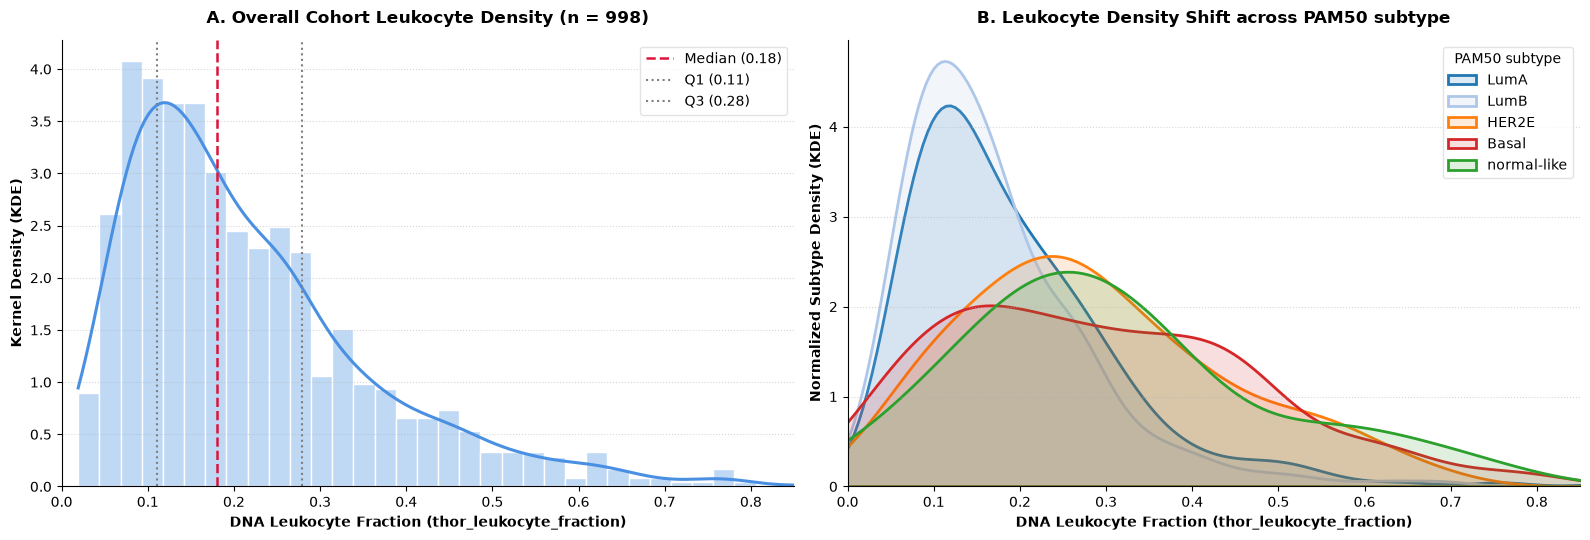

In [17]:
# =============================================================================
# Diagnostic Visualization: Density Distribution of Leukocyte Fraction
# =============================================================================

# Clean non-null values for leukocyte fraction
df_clean = molecular.dropna(subset=["thor_leukocyte_fraction"]).copy()
df_pam = molecular.dropna(subset=["thor_leukocyte_fraction", SUBTYPE_COL]).copy()

subtype_order = [s for s in SUBTYPE_ORDER if s in df_pam[SUBTYPE_COL].unique()]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# -----------------------------------------------------------------------------
# Panel A: Overall Cohort Density Distribution
# -----------------------------------------------------------------------------
ax1 = axes[0]
sns.histplot(df_clean["thor_leukocyte_fraction"], kde=True, color="#4a90e2", 
             stat="density", bins=35, alpha=0.35, edgecolor="white", ax=ax1,
             line_kws=dict(linewidth=2.2, color="#1b4f72"))

# Summary statistics
med = df_clean["thor_leukocyte_fraction"].median()
q25 = df_clean["thor_leukocyte_fraction"].quantile(0.25)
q75 = df_clean["thor_leukocyte_fraction"].quantile(0.75)

# Annotate median and quartiles
ax1.axvline(med, color="crimson", linestyle="--", linewidth=1.8, label=f"Median ({med:.2f})")
ax1.axvline(q25, color="gray", linestyle=":", linewidth=1.5, label=f"Q1 ({q25:.2f})")
ax1.axvline(q75, color="gray", linestyle=":", linewidth=1.5, label=f"Q3 ({q75:.2f})")

ax1.set_title(f"A. Overall Cohort Leukocyte Density (n = {len(df_clean)})", fontsize=12, fontweight="bold", pad=12)
ax1.set_xlabel("DNA Leukocyte Fraction (thor_leukocyte_fraction)", fontsize=10, fontweight="bold")
ax1.set_ylabel("Kernel Density (KDE)", fontsize=10, fontweight="bold")
ax1.set_xlim(0, 0.85)
ax1.grid(axis="y", linestyle=":", alpha=0.5)
ax1.legend(frameon=True, facecolor="white", edgecolor="#dcdcdc", loc="upper right")

# -----------------------------------------------------------------------------
# Panel B: Stratified Density by subtype Subtype
# -----------------------------------------------------------------------------
ax2 = axes[1]

for s in subtype_order:
    sub_data = df_pam[df_pam[SUBTYPE_COL] == s]["thor_leukocyte_fraction"]
    sns.kdeplot(sub_data, label=s, color=SUBTYPE_COLORS.get(s, "#cccccc"), 
                fill=True, alpha=0.15, linewidth=2.0, common_norm=False, ax=ax2)

ax2.set_title(f"B. Leukocyte Density Shift across {SUBTYPE_LABEL}", fontsize=12, fontweight="bold", pad=12)
ax2.set_xlabel("DNA Leukocyte Fraction (thor_leukocyte_fraction)", fontsize=10, fontweight="bold")
ax2.set_ylabel("Normalized Subtype Density (KDE)", fontsize=10, fontweight="bold")
ax2.set_xlim(0, 0.85)
ax2.grid(axis="y", linestyle=":", alpha=0.5)
ax2.legend(title=f"{SUBTYPE_LABEL}", frameon=True, facecolor="white", edgecolor="#dcdcdc", loc="upper right")

# Polish layout
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Observations (breast)**
- Basal-like tumours are mostly C2 (IFN-γ dominant); Luminal A has the most C3 (inflammatory); no C5, as expected outside gliomas.
- Leukocyte fraction is strongly anti-correlated with purity, and only moderately correlated with the H&E TIL estimate of Saltz et al.
- CIBERSORT values are used as the composition of the immune infiltrate, not for cell-type concordance with OpenTME.

## 7. Somatic driver mutations (MC3)

**Sources:**
- **Mutations:** MC3 public MAF ([Ellrott et al., *Cell Syst* 2018](https://gdc.cancer.gov/about-data/publications/mc3-2017)), consensus somatic calls from whole-exome sequencing, all cancers (~3.6 M mutations; read in chunks keeping only cohort patients).
- **Driver genes:** [Bailey et al., *Cell* 2018](https://doi.org/10.1016/j.cell.2018.02.060), Table S1 (download by hand): consensus driver genes per cancer type.

**Steps**
- Quality filter: a mutation is kept if all its `FILTER` labels are allowed (`PASS`, `wga`, `native_wga_mix`). `wga` marks every mutation of a sample whose DNA was amplified, not suspicious calls; keeping only `PASS` would create false "not mutated" patients.
- **Non-silent** coding mutations only (missense, nonsense, frameshift and in-frame indels, splice site, start/stop codon changes).
- A patient is **profiled** if their primary tumour is in the MAF; patients not profiled stay `NaN`, never `0`.
- Restrict to the **driver genes of the indication** (long genes such as TTN accumulate mutations by chance) mutated in at least 5 % of profiled patients (`min_freq`), as `mut_<GENE>` (1 mutated, 0 profiled and not mutated).

In [18]:
mu = TM["mutations"]
maf = tcga.read_maf(src("mc3")["path"], patients, mu["columns"])
print(f"Mutations in cohort patients: {len(maf):,} | samples: {maf['Tumor_Sample_Barcode'].nunique()}")
display(maf["Variant_Classification"].value_counts().to_frame().T)
display(maf["FILTER"].value_counts().head(15).to_frame().T)

Mutations in cohort patients: 126,988 | samples: 961


Variant_Classification,Missense_Mutation,Silent,Frame_Shift_Del,3'UTR,Nonsense_Mutation,Intron,5'UTR,Splice_Site,RNA,Frame_Shift_Ins,3'Flank,In_Frame_Del,5'Flank,Translation_Start_Site,Nonstop_Mutation,In_Frame_Ins
count,65200,24208,9223,8747,5506,4315,3206,1995,1599,913,659,656,545,87,82,47


FILTER,PASS,wga,nonpreferredpair,native_wga_mix,StrandBias,"nonpreferredpair,wga",common_in_exac,"common_in_exac,wga","StrandBias,wga",oxog,"StrandBias,nonpreferredpair","StrandBias,oxog","StrandBias,native_wga_mix","common_in_exac,native_wga_mix","common_in_exac,nonpreferredpair"
count,85360,30285,3839,3766,1711,820,507,184,157,129,58,56,49,32,20


In [19]:
maf_ok = maf[tcga.passes_filter(maf["FILTER"], set(mu["allowed_filters"]))]
samples = primary(pd.DataFrame({"Tumor_Sample_Barcode": maf_ok["Tumor_Sample_Barcode"].unique()}),
                  "Tumor_Sample_Barcode", "MC3")
profiled = pd.Index(samples["patient"], name="patient")
maf_ns = maf_ok[maf_ok["Tumor_Sample_Barcode"].isin(samples["Tumor_Sample_Barcode"])
                & maf_ok["Variant_Classification"].isin(mu["nonsilent"])]
print(f"Profiled patients: {len(profiled)} / {len(patients)} | non-silent mutations kept: {len(maf_ns):,}")

mut_matrix = tcga.mutation_matrix(maf_ns, profiled)
maf_ns.to_parquet(P["tcga_mutations"], index=False)
mut_matrix.shape

[MC3] sample types: {'01': 956}
[MC3] 956 patients -> 956 with a primary tumour sample (0 extra primary samples dropped)
Profiled patients: 956 / 1025 | non-silent mutations kept: 78,983


(956, 16405)

In [20]:
spec = src("bailey")
bailey = pd.read_excel(spec["path"], sheet_name=spec["sheet"], header=spec["header"])
bailey.columns = bailey.columns.str.strip()
drivers = sorted(bailey.loc[bailey["Cancer"] == TCGA_CODE, "Gene"].unique())
print(f"{len(drivers)} {TCGA_CODE} driver genes (Bailey 2018):", drivers)

MIN_FREQ = mu["min_freq"]
freq = tcga.mutation_frequencies(mut_matrix, drivers, MIN_FREQ)
keep_genes = freq.index[freq["kept"]].tolist()
print(f"Kept (>= {MIN_FREQ:.0%} of {len(profiled)} profiled patients):", keep_genes)

29 BRCA driver genes (Bailey 2018): ['AKT1', 'ARID1A', 'BRCA1', 'CASP8', 'CBFB', 'CDH1', 'CDKN1B', 'CHD4', 'CTCF', 'ERBB2', 'FBXW7', 'FOXA1', 'GATA3', 'GPS2', 'KMT2C', 'KRAS', 'MAP2K4', 'MAP3K1', 'NCOR1', 'NF1', 'PIK3CA', 'PIK3R1', 'PTEN', 'PTPRD', 'RB1', 'RUNX1', 'SF3B1', 'TBX3', 'TP53']
Kept (>= 5% of 956 profiled patients): ['TP53', 'PIK3CA', 'GATA3', 'CDH1', 'KMT2C', 'MAP3K1', 'PTEN']


/Users/Admin/Desktop/GitHub/opentme-tcga-integration/.venv/lib/python3.12/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


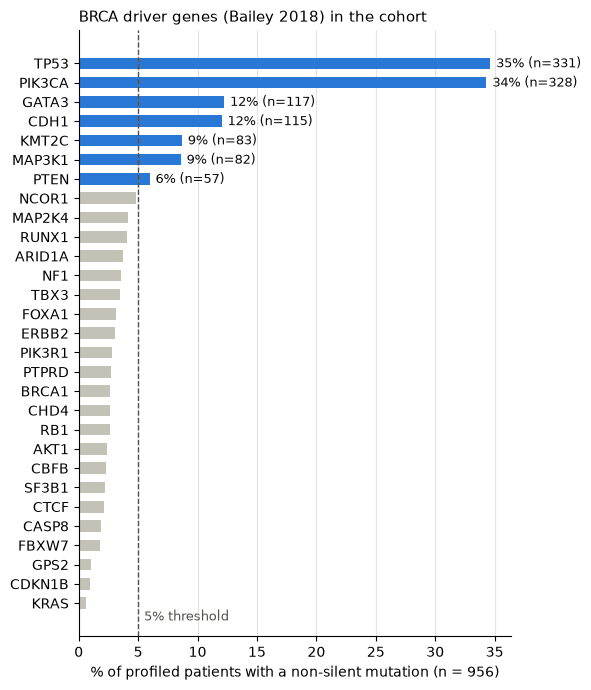

In [21]:
BLUE, GREY = "#2a78d6", "#c3c2b7"
plot_df = freq.sort_values("freq")

fig, ax = plt.subplots(figsize=(6, 7))
ax.barh(plot_df.index, plot_df["freq"] * 100, height=0.6,
        color=[BLUE if k else GREY for k in plot_df["kept"]])
ax.axvline(MIN_FREQ * 100, color="#52514e", lw=1, ls="--")
ax.text(MIN_FREQ * 100 + 0.5, -0.9, f"{MIN_FREQ:.0%} threshold", color="#52514e", fontsize=9)

# Labels only on the kept genes
for gene, row in plot_df[plot_df["kept"]].iterrows():
    ax.text(row["freq"] * 100 + 0.5, gene, f"{row['freq']:.0%} (n={row['n_mutated']})",
            va="center", fontsize=9, color="#0b0b0b")

ax.set_xlabel(f"% of profiled patients with a non-silent mutation (n = {len(profiled)})")
ax.set_title(f"{TCGA_CODE} driver genes (Bailey 2018) in the cohort", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e4e0", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### 7.1 Combinations and co-occurrence of the kept drivers

In [22]:
mut_bool = mut_matrix[keep_genes].astype(bool)
combo = mut_bool.apply(lambda r: " + ".join(g for g in keep_genes if r[g]) or "none", axis=1)
combos = combo.value_counts().to_frame("n_patients")
combos["pct"] = (100 * combos["n_patients"] / len(profiled)).round(1)
display(combos.head(20))

tcga.cooccurrence(mut_bool).round(3)

,n_patients,pct
TP53,210,22.0
none,197,20.6
PIK3CA,117,12.2
GATA3,61,6.4
TP53 + PIK3CA,57,6.0
PIK3CA + CDH1,40,4.2
CDH1,37,3.9
PIK3CA + MAP3K1,30,3.1
PIK3CA + GATA3,20,2.1
MAP3K1,18,1.9


,gene_a,gene_b,both,odds_ratio,p,q,pattern
2,TP53,CDH1,9,0.137,0.000,0.000,exclusive
1,TP53,GATA3,10,0.151,0.000,0.000,exclusive
0,TP53,PIK3CA,76,0.441,0.000,0.000,exclusive
4,TP53,MAP3K1,9,0.211,0.000,0.000,exclusive
7,PIK3CA,CDH1,56,1.986,0.001,0.003,co-occur
9,PIK3CA,MAP3K1,42,2.159,0.001,0.003,co-occur
8,PIK3CA,KMT2C,42,2.103,0.002,0.005,co-occur
6,PIK3CA,GATA3,27,0.536,0.007,0.018,exclusive
18,KMT2C,MAP3K1,14,2.402,0.012,0.027,co-occur
11,GATA3,CDH1,7,0.431,0.033,0.069,-


In [23]:
mutations = mut_matrix[keep_genes].add_prefix("mut_")
mutations["mut_profiled"] = 1
desc = {f"mut_{g}": f"{g}: non-silent mutation (1) vs profiled not mutated (0); "
                    f"{freq.loc[g, 'n_mutated']} mutated ({freq.loc[g, 'freq']:.1%})" for g in keep_genes}
desc["mut_profiled"] = "Tumour exome profiled in MC3 (1); NaN = not profiled"
table.add(mutations, source=f"MC3 public MAF; {TCGA_CODE} drivers from Bailey 2018", level="main", descriptions=desc)
molecular = table.data

# Sanity checks: mutations by subtype, and agreement with Thorsson's mutation rate
display(molecular.groupby(SUBTYPE_COL)[[f"mut_{g}" for g in keep_genes]].mean().round(2))
n_mut = maf_ns.groupby(to_patient(maf_ns["Tumor_Sample_Barcode"]).to_numpy()).size().reindex(molecular.index)
print("Spearman n mutations vs thor_tmb:", round(n_mut.corr(molecular["thor_tmb"], method="spearman"), 2))
if {"clin_histology", "mut_CDH1"} <= set(molecular):
    display(pd.crosstab(molecular["clin_histology"], molecular["mut_CDH1"], margins=True))

,mut_TP53,mut_PIK3CA,mut_GATA3,mut_CDH1,mut_KMT2C,mut_MAP3K1,mut_PTEN
clin_pam50,,,,,,,
Basal,0.90,0.07,0.00,0.01,0.05,0.03,0.05
HER2E,0.69,0.31,0.04,0.05,0.09,0.04,0.07
LumA,0.11,0.47,0.15,0.20,0.10,0.14,0.06
LumB,0.34,0.30,0.20,0.05,0.10,0.04,0.06
normal-like,0.31,0.19,0.03,0.16,0.00,0.03,0.06


Spearman n mutations vs thor_tmb: 0.98


mut_CDH1,0.0,1.0,All
clin_histology,,,
ductal,696,15,711
lobular,58,91,149
mixed,21,5,26
other,65,4,69
All,840,115,955


**Observations (breast)**
- `wga` affects a sizeable share of samples; keeping only `PASS` would have turned their patients into false "not mutated".
- Seven drivers pass 5 %: TP53, PIK3CA, CDH1, GATA3, KMT2C, MAP3K1, PTEN.
- TP53 is mutually exclusive with GATA3, CDH1, MAP3K1 and PIK3CA (basal vs luminal biology); PIK3CA co-occurs with MAP3K1, CDH1 and KMT2C. Analyses of genomic alterations therefore adjust for PAM50 (and histology for CDH1).
- CDH1 is mutated in most lobular tumours but almost never in ductal ones: within ductal tumours a CDH1 comparison is not powered.
- The number of mutations agrees closely with Thorsson's mutation rate, so the processing is consistent.

## 8. Oncogenic signalling pathways (Sanchez-Vega et al., 2018)

**Source:** [Sanchez-Vega et al., *Cell* 2018](https://doi.org/10.1016/j.cell.2018.03.035), Table S4 (download by hand): for each PanCanAtlas tumour, whether each of ten canonical pathways (cell cycle, Hippo, Myc, Notch, Nrf2, PI3K, RTK-RAS, TP53, TGF-β, Wnt) is altered (1) or not (0), counting mutations, **copy-number changes** and fusions. Many drivers are focal amplifications or deletions (e.g. ERBB2, CCND1, MYC, CDKN2A in breast) that the MAF does not capture, and alterations in different genes of the same pathway are aggregated.

A pathway and its dominant gene (e.g. `path_tp53` and `mut_TP53`) should not enter the same model.

In [24]:
spec = src("sanchez_vega")
pw = TM["pathways"]
path_all = pd.read_excel(spec["path"], sheet_name=spec["sheet"])
path_all.columns = path_all.columns.astype(str).str.strip()
path_cohort = path_all[to_patient(path_all[pw["sample_column"]]).isin(set(patients)).to_numpy()]
pathways = primary(path_cohort, pw["sample_column"], "Sanchez-Vega").set_index("patient")[pw["names"]]
pathways.columns = ["path_" + tcga.snake(c) for c in pathways.columns]
print(format_coverage("Sanchez-Vega", tcga.coverage(pathways.index, patients)))
table.add(pathways, source="Sanchez-Vega et al. 2018 (Table S4)", level="secondary",
          descriptions={c: f"Pathway altered (1) or not (0): {c.removeprefix('path_')} "
                           "(mutations, copy number or fusions)" for c in pathways.columns})
molecular = table.data
molecular.filter(like="path_").mean().round(2).sort_values(ascending=False).to_frame("fraction altered").T

[Sanchez-Vega] sample types: {'01': 921}
[Sanchez-Vega] 921 patients -> 921 with a primary tumour sample (0 extra primary samples dropped)
[Sanchez-Vega] cohort patients with data: 921 / 1025 (89.9 %); first missing: ['TCGA-A1-A0SM', 'TCGA-A2-A0CO', 'TCGA-A2-A0CY', 'TCGA-A2-A0CZ', 'TCGA-A2-A3KC']


,path_pi3k,path_cell_cycle,path_tp53,path_rtk_ras,path_myc,path_notch,path_wnt,path_hippo,path_tgf_beta,path_nrf2
fraction altered,0.56,0.48,0.47,0.4,0.21,0.21,0.18,0.09,0.06,0.02


In [25]:
PATH_GENES = cfg["tcga_molecular"].get("pathway_genes", {})
for p, genes in PATH_GENES.items():
    for g in genes:
        if {p, g} <= set(molecular):
            display(pd.crosstab(molecular[p], molecular[g], margins=True))

mut_TP53,0.0,1.0,All
path_tp53,,,
0.0,492,0,492
1.0,103,326,429
All,595,326,921


mut_PIK3CA,0.0,1.0,All
path_pi3k,,,
0.0,403,5,408
1.0,197,316,513
All,600,321,921


mut_PTEN,0.0,1.0,All
path_pi3k,,,
0.0,407,1,408
1.0,461,52,513
All,868,53,921


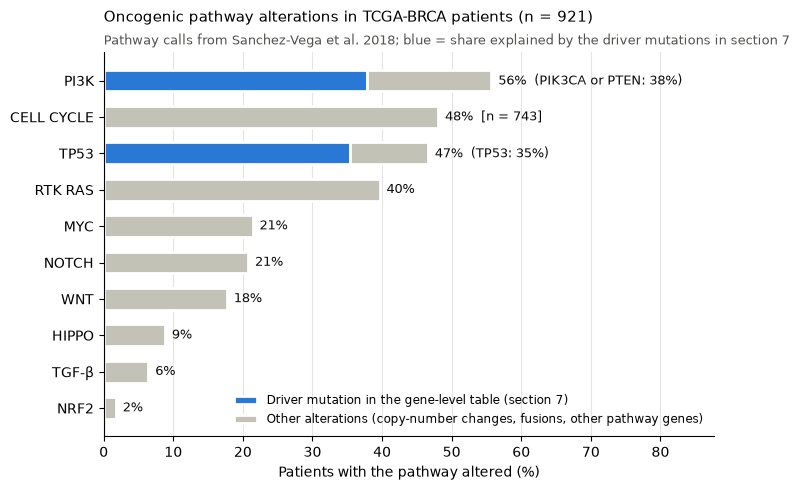

In [26]:
BLUE, GREY, MUTED = "#2a78d6", "#c3c2b7", "#52514e"

path_cols = [c for c in molecular.columns if c.startswith("path_")]

# Each pathway uses all patients in which it was evaluated (no patient dropped because of another pathway)
rows = []
for p in path_cols:
    d = molecular[molecular[p].notna()]
    altered = d[p] == 1
    genes = [g for g in PATH_GENES.get(p, []) if g in d]
    with_mut = (altered & d[genes].eq(1).any(axis=1)) if genes else pd.Series(False, index=d.index)
    rows.append({"pathway": p.removeprefix("path_").replace("_", " ").upper().replace("TGF BETA", "TGF-β"),
                 "with_mutation": 100 * with_mut.mean(),
                 "other": 100 * (altered & ~with_mut).mean(),
                 "genes": " or ".join(g.removeprefix("mut_") for g in genes),
                 "n": len(d)})
fig_df = pd.DataFrame(rows).assign(total=lambda x: x["with_mutation"] + x["other"]).sort_values("total")
n_total = molecular[path_cols].notna().any(axis=1).sum()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(fig_df["pathway"], fig_df["with_mutation"], height=0.6, color=BLUE, edgecolor="white", linewidth=2,
        label="Driver mutation in the gene-level table (section 7)")
ax.barh(fig_df["pathway"], fig_df["other"], left=fig_df["with_mutation"], height=0.6, color=GREY,
        edgecolor="white", linewidth=2,
        label="Other alterations (copy-number changes, fusions, other pathway genes)")

for _, r in fig_df.iterrows():
    label = f"{r['total']:.0f}%"
    if r["genes"]:
        label += f"  ({r['genes']}: {r['with_mutation']:.0f}%)"
    if r["n"] < n_total:
        label += f"  [n = {r['n']}]"
    ax.text(r["total"] + 1, r["pathway"], label, va="center", fontsize=9, color="#0b0b0b")

ax.set_xlabel("Patients with the pathway altered (%)")
ax.set_xlim(0, fig_df["total"].max() + 32)
ax.set_title(f"Oncogenic pathway alterations in {TCGA_PROJECT} patients (n = {n_total})",
             loc="left", fontsize=11, pad=22)
ax.text(0, 1.02, "Pathway calls from Sanchez-Vega et al. 2018; blue = share explained by the driver mutations "
                 "in section 7", transform=ax.transAxes, fontsize=9, color=MUTED)
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e4e0", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Observations (breast)**
- PI3K, cell cycle, TP53 and RTK-RAS are the most altered pathways, as expected; Hippo, TGF-β and Nrf2 are too rare to be analysed.
- All TP53-mutated tumours have the TP53 pathway altered, plus tumours without a TP53 mutation (e.g. MDM2/MDM4 amplification).
- Many PI3K-altered tumours have no PIK3CA mutation (PTEN loss, AKT1 or PIK3R1 mutation, PIK3CA amplification).
- Cell cycle was not evaluated in some tumours, so each pathway uses all patients in which it was evaluated.
- Pathways complement the gene-level table rather than repeat it.

## 9. Chromosome arm-level aneuploidy (Taylor et al., 2018)

**Source:** arm-level calls from [Taylor et al., *Cancer Cell* 2018](https://doi.org/10.1016/j.ccell.2018.03.007), as distributed in the cBioPortal PanCancer Atlas study (downloaded automatically).

Aneuploidy, the gain or loss of whole chromosome arms, alters hundreds of genes at once and is distinct from focal copy-number changes (section 8) and point mutations (section 7). Calls are converted to 1 (gain), −1 (loss) and 0 (unchanged). Events (arm × direction) present in at least `min_event_freq` of patients are kept as binary variables (`NaN` = arm not called); events listed in `required_events` (breast: 16q loss, which carries CDH1) are kept whatever their frequency.

In [27]:
spec = src("arm_level")
ar = {**TM["arm_level"]}
arms_raw = pd.read_csv(spec["path"], sep="\t", comment="#")
calls = tcga.arm_calls(arms_raw, ar["arm_column"], ar["calls"])
print(f"Samples: {len(calls)} | values: {pd.unique(calls.drop(columns='sample').values.ravel())}")

arms = primary(calls, "sample", "Arm-level CNA").set_index("patient").drop(columns="sample")
arms = arms.loc[arms.index.isin(patients)]
print(format_coverage("Arm-level CNA", tcga.coverage(arms.index, patients)))

MIN_EVENT_FREQ = ar["min_event_freq"]
arm_table, events = tcga.arm_events(arms, MIN_EVENT_FREQ, ar.get("required_events", []))
arm_freq = tcga.arm_frequencies(arms)
kept_events = events[events["kept"]].sort_values("freq", ascending=False)
display(kept_events[["arm", "direction", "freq"]])

desc = {f"aneu_{r.event}": f"Chromosome arm {r.arm} {r.direction} (1) vs not (0); {r.freq:.0%} of patients (Taylor 2018)"
        for r in kept_events.itertuples()}
secondary = [f"aneu_{e}" for e in ar.get("secondary_events", [])]
table.add(arm_table[secondary], source="Taylor 2018 via cBioPortal", level="secondary", descriptions=desc)
table.add(arm_table.drop(columns=secondary), source="Taylor 2018 via cBioPortal", level="exploratory", descriptions=desc)
molecular = table.data

Samples: 1084 | values: [ 0. nan -1.  1.]
[Arm-level CNA] sample types: {'01': 1084}
[Arm-level CNA] 1084 patients -> 1084 with a primary tumour sample (0 extra primary samples dropped)
[Arm-level CNA] cohort patients with data: 1012 / 1025 (98.7 %); first missing: ['TCGA-A2-A0CY', 'TCGA-A8-A084', 'TCGA-A8-A08F', 'TCGA-A8-A08S', 'TCGA-A8-A09E']


,arm,direction,freq
1,1q,gain,0.586957
67,16q,loss,0.526680
68,17p,loss,0.526680
53,8p,loss,0.416996
27,16p,gain,0.401186
15,8q,gain,0.393281
77,22q,loss,0.368577
63,13q,loss,0.333004
36,20q,gain,0.316206


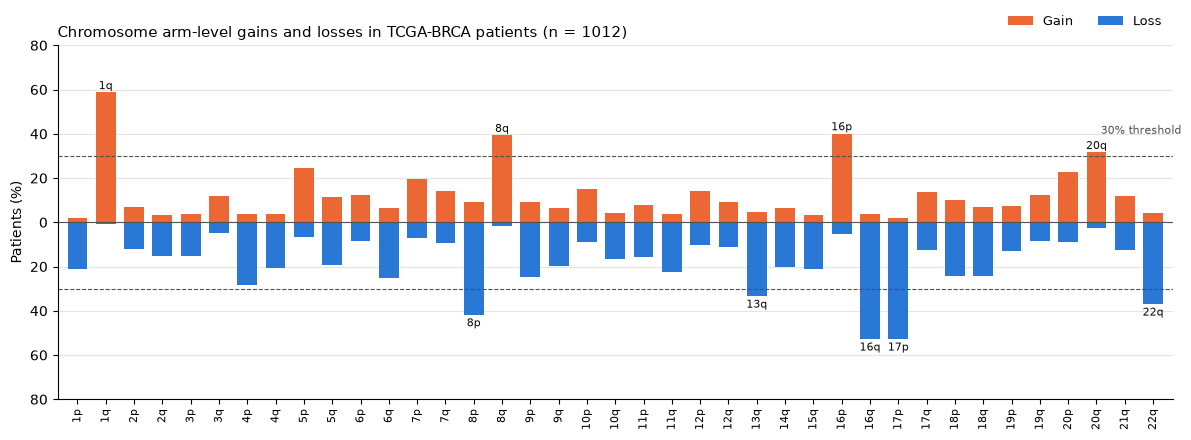

In [28]:
GAIN, LOSS, MUTED = "#eb6834", "#2a78d6", "#52514e"

# Arms in genome order (1p, 1q, 2p, …, 22q)
order = sorted(arm_freq.index, key=lambda a: (int(a[:-1]), a[-1]))
f = arm_freq.loc[order] * 100
x = np.arange(len(order))
kept = set(zip(kept_events["arm"], kept_events["direction"]))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x, f["gain"], width=0.7, color=GAIN, label="Gain")
ax.bar(x, -f["loss"], width=0.7, color=LOSS, label="Loss")
ax.axhline(0, color=MUTED, lw=0.8)
for y in (MIN_EVENT_FREQ * 100, -MIN_EVENT_FREQ * 100):
    ax.axhline(y, color=MUTED, lw=0.8, ls="--")
ax.text(len(order), MIN_EVENT_FREQ * 100 + 10, f"{MIN_EVENT_FREQ:.0%} threshold",
        ha="right", fontsize=8, color=MUTED)

# Label the kept events
for i, arm in enumerate(order):
    if (arm, "gain") in kept:
        ax.text(i, f.loc[arm, "gain"] + 1.5, arm, ha="center", fontsize=8, color="#0b0b0b")
    if (arm, "loss") in kept:
        ax.text(i, -f.loc[arm, "loss"] - 1.5, arm, ha="center", va="top", fontsize=8, color="#0b0b0b")

ax.set_xticks(x, order, rotation=90, fontsize=8)
ax.set_xlim(-0.7, len(order) - 0.3)
lim = max(f["gain"].max(), f["loss"].max()) + 10
ax.set_ylim(-lim, lim)
ax.set_yticks(ax.get_yticks(), [f"{abs(t):.0f}" for t in ax.get_yticks()])
ax.set_ylabel("Patients (%)")
ax.set_title(f"Chromosome arm-level gains and losses in {TCGA_PROJECT} patients (n = {len(arms)})",
             loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper right", fontsize=9, ncols=2, bbox_to_anchor=(1, 1.12))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [29]:
# Number of altered arms vs Thorsson's aneuploidy score
n_altered = (arms != 0).sum(axis=1).reindex(molecular.index)
print("Spearman n altered arms vs thor_aneuploidy_score:",
      round(n_altered.corr(molecular["thor_aneuploidy_score"], method="spearman"), 2))

Spearman n altered arms vs thor_aneuploidy_score: 0.84


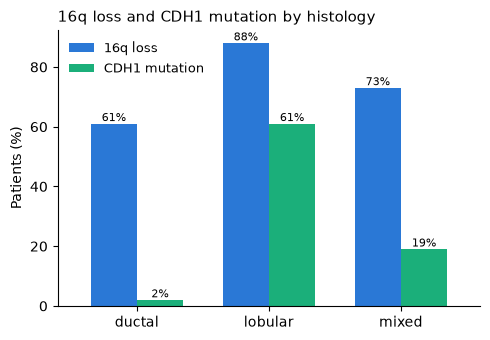

In [30]:
# Breast: 16q loss and CDH1 mutation by histology
if {'aneu_16q_loss', 'mut_CDH1', 'clin_histology'} <= set(molecular):
    LOSS = "#2a78d6"
    d = molecular[molecular["clin_histology"].isin(["ductal", "lobular", "mixed"])]
    summary = (d.groupby("clin_histology")[["aneu_16q_loss", "mut_CDH1"]].mean() * 100).round(0)

    ax = summary.plot.bar(figsize=(5, 3.5), color=[LOSS, "#1baf7a"], width=0.7, rot=0)
    ax.set_ylabel("Patients (%)")
    ax.set_xlabel("")
    ax.set_title("16q loss and CDH1 mutation by histology", loc="left", fontsize=11)
    ax.legend(["16q loss", "CDH1 mutation"], frameon=False, fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.0f%%", fontsize=8)
    plt.tight_layout()
    plt.show()

**Observations (breast)**
- Nine events pass 30 % (a natural break in the frequencies): 1q gain, 16q loss, 17p loss (TP53), 8p loss, 16p gain, 8q gain (MYC), 22q loss, 13q loss (RB1), 20q gain, the classic breast cancer events.
- 16q loss is frequent in all histologies, while CDH1 mutation is almost only lobular: what defines lobular carcinoma is the loss of both CDH1 copies, not 16q loss alone.
- Genomic instability has two axes, chromosomal (aneuploidy, genome doubling, ploidy) and mutational / DNA repair (TMB, HRD): models should use one variable per axis.

## 10. Hypoxia (Bhandari et al., 2019)

**Source:** [Bhandari et al., *Nat Genet* 2019](https://doi.org/10.1038/s41588-018-0318-2), hypoxia scores (Buffa, Ragnum, Winter) from the cBioPortal PanCancer Atlas study (downloaded automatically).

Hypoxia arises when tumour growth outpaces the blood supply; it triggers necrosis and angiogenesis and favours an immunosuppressive microenvironment. The Buffa score is the main variable (`main_score`).

In [31]:
spec = src("hypoxia")
HYP = TM["hypoxia"]
hyp_raw = pd.read_csv(spec["path"], sep="\t", comment="#")
score_cols = [c for c in hyp_raw.columns if "HYPOXIA" in c.upper()]
hyp = (hyp_raw.assign(patient=to_patient(hyp_raw[HYP["id_column"]]).to_numpy())
              .set_index("patient")[score_cols].apply(pd.to_numeric, errors="coerce"))
assert hyp.index.is_unique, "More than one row per patient"
hyp.columns = ["hyp_" + c.lower().replace("_hypoxia_score", "") for c in hyp.columns]
print(format_coverage("Hypoxia", tcga.coverage(hyp.index, patients)))

table.add(hyp[[HYP["main_score"]]], source="cBioPortal (Bhandari 2019)", level="main",
          descriptions={HYP["main_score"]: f"Hypoxia score: {HYP['main_score'].removeprefix('hyp_')} (Bhandari 2019)"})
molecular = table.data

# The three scores against each other and against proliferation
display(hyp.join(molecular["thor_proliferation"]).corr(method="spearman").round(2))
molecular.groupby(SUBTYPE_COL)[HYP["main_score"]].median().round(1).sort_values(ascending=False)

[Hypoxia] cohort patients with data: 1010 / 1025 (98.5 %); first missing: ['TCGA-A2-A0CY', 'TCGA-A8-A084', 'TCGA-A8-A08F', 'TCGA-A8-A08S', 'TCGA-A8-A09E']


,hyp_buffa,hyp_winter,hyp_ragnum,thor_proliferation
hyp_buffa,1.00,0.85,0.77,0.74
hyp_winter,0.85,1.00,0.67,0.58
hyp_ragnum,0.77,0.67,1.00,0.88
thor_proliferation,0.74,0.58,0.88,1.00


clin_pam50
Basal          19.0
HER2E           9.0
LumB           -7.0
normal-like   -21.0
LumA          -27.0
Name: hyp_buffa, dtype: float64

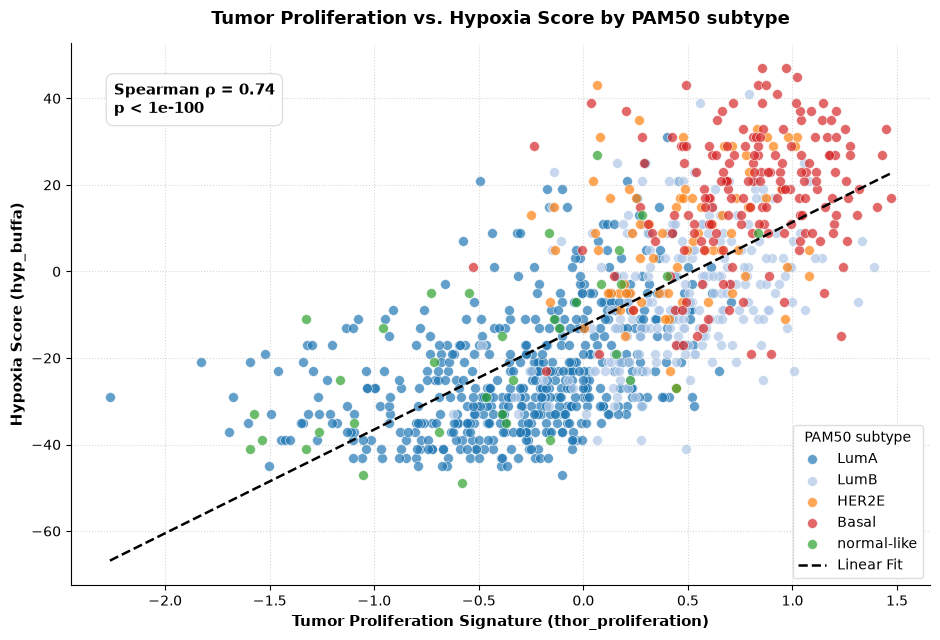

In [32]:
# =============================================================================
# Diagnostic Visualization: Proliferation vs. Hypoxia by subtype Subtype
# =============================================================================

hyp_col = HYP["main_score"]

# Filter patients with valid proliferation, hypoxia, and subtype values
df_plot = molecular.dropna(subset=["thor_proliferation", hyp_col, SUBTYPE_COL]).copy()

subtype_order = [s for s in SUBTYPE_ORDER if s in df_plot[SUBTYPE_COL].unique()]

# 2. Calculate Spearman correlation
rho, pval = spearmanr(df_plot["thor_proliferation"], df_plot[hyp_col])

fig, ax = plt.subplots(figsize=(9.5, 6.5))

# Scatter points by subtype
for s in subtype_order:
    sub = df_plot[df_plot[SUBTYPE_COL] == s]
    ax.scatter(sub["thor_proliferation"], sub[hyp_col],
               color=SUBTYPE_COLORS.get(s, "#cccccc"), label=s,
               alpha=0.7, edgecolors="white", linewidth=0.5, s=50)

# Linear trend line
m, b = np.polyfit(df_plot["thor_proliferation"], df_plot[hyp_col], 1)
x_vals = np.linspace(df_plot["thor_proliferation"].min(), df_plot["thor_proliferation"].max(), 100)
ax.plot(x_vals, m * x_vals + b, color="black", linestyle="--", linewidth=1.8, label="Linear Fit")

# Statistical annotation box in upper left
ax.text(0.05, 0.93, f"Spearman ρ = {rho:.2f}\np < 1e-100", transform=ax.transAxes,
        fontsize=11, fontweight="bold", verticalalignment="top",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#dcdcdc", alpha=0.9))

# Titles and aesthetics
ax.set_title(f"Tumor Proliferation vs. Hypoxia Score by {SUBTYPE_LABEL}", fontsize=13, fontweight="bold", pad=14)
ax.set_xlabel("Tumor Proliferation Signature (thor_proliferation)", fontsize=11, fontweight="bold")
ax.set_ylabel(f"Hypoxia Score ({hyp_col})", fontsize=11, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.5)
ax.spines[["top", "right"]].set_visible(False)

# Legend placed in the empty lower-right corner (never obscured)
ax.legend(title=f"{SUBTYPE_LABEL}", loc="lower right", frameon=True, 
          facecolor="white", edgecolor="#dcdcdc", framealpha=0.95, fontsize=10)

plt.tight_layout()
plt.show()

**Observations (breast)**
- The three scores correlate strongly; Buffa follows the expected subtype gradient (highest in Basal-like, lowest in Luminal A).
- Hypoxia overlaps strongly with proliferation, so hypoxia analyses adjust for proliferation, and the hypoxia target is compared with the proliferation target in the models.

## 11. Transcriptome: functional TME signatures

**Expression:** UCSC Xena Pan-Cancer `HiSeqV2` (RSEM gene level, log2(x + 1); download by hand).

Biological processes are represented by multi-gene signatures rather than single genes, to reduce noise and multiple testing:
- **29 functional TME signatures** ([Bagaev et al., *Cancer Cell* 2021](https://doi.org/10.1016/j.ccell.2021.04.014), Table S1): angiogenesis, fibroblasts and matrix, immune infiltrate and tumour properties.
- **12-chemokine TLS signature** ([Messina et al., *Sci Rep* 2012](https://doi.org/10.1038/srep00765)) and its three organiser chemokines (CXCL13, CCL19, CCL21).
- **Hallmark glycolysis** (MSigDB).

Following Bagaev et al., signatures are scored per sample with single-sample GSEA (ssGSEA), then median-centred and scaled by the median absolute deviation, which is robust to the few tumours with extreme immune values. **Single genes** listed in the indication file are added as `expr_<GENE>` (breast: COL10A1, a CAF marker of immune exclusion, Hammerl 2021).

In [33]:
rna_raw = pd.read_csv(src("rna")["path"], sep="\t", index_col=0)
assert rna_raw.index.is_unique, "Duplicate gene symbols"
samples_rna = primary(pd.DataFrame({"sample": rna_raw.columns}), "sample", "RNA")
samples_rna = samples_rna[samples_rna["patient"].isin(patients)]
rna = rna_raw[samples_rna["sample"]].set_axis(samples_rna["patient"], axis=1)
rna.columns.name = "patient"
del rna_raw
print(f"Genes x patients: {rna.shape}; values from {rna.min().min():.2f} to {rna.max().max():.2f}")
print(format_coverage("RNA", tcga.coverage(rna.columns, patients)))
rna.to_parquet(P["tcga_rna"])

genes = TM.get("single_genes", [])
missing = [g for g in genes if g not in rna.index]
assert not missing, f"Single genes not in the matrix: {missing}"
if genes:
    table.add(rna.loc[genes].T.add_prefix("expr_"), source="Xena HiSeqV2 (log2 RSEM)", level="main",
              descriptions={f"expr_{g}": f"{g} expression, log2(RSEM + 1)" for g in genes})

[RNA] sample types: {'01': 1097, '11': 114, '06': 7}
[RNA] 1097 patients -> 1097 with a primary tumour sample (0 extra primary samples dropped)
Genes x patients: (20530, 1023); values from 0.00 to 20.98
[RNA] cohort patients with data: 1023 / 1025 (99.8 %); first missing: ['TCGA-AC-A5EI', 'TCGA-C8-A9FZ']


In [34]:
spec = src("bagaev")
bag = pd.read_excel(spec["path"], sheet_name=spec["sheet"], header=spec["header"])
bag["Gene signature"] = bag["Gene signature"].str.strip()
bag["Gene"] = bag["Gene"].astype(str).str.strip()
# Gene names turned into dates by Excel would appear here
print("Date-like gene names:", bag.loc[bag["Gene"].str.contains(r"\d{4}-\d{2}-\d{2}|^\d+-[A-Za-z]{3}$"), "Gene"].tolist())

sg = TM["signatures"]
signatures = {tcga.snake(name): list(g) for name, g in bag.groupby("Gene signature")["Gene"]}
print("Bagaev signatures:", len(signatures))
signatures.update(sg["extra"])
library = gp.get_library(name=sg["msigdb_library"], organism="Human")
signatures.update({name: library[term] for name, term in sg["msigdb_sets"].items()})
signatures = tcga.map_aliases(signatures, sg["aliases"])

for name, g in signatures.items():
    absent = [x for x in g if x not in rna.index]
    print(f"{name:42s} {len(g):4d} genes, missing {len(absent)}: {absent}")

Date-like gene names: []
Bagaev signatures: 29
angiogenesis                                 15 genes, missing 0: []
antitumor_cytokines                           6 genes, missing 0: []
b_cells                                      13 genes, missing 0: []
cancer_associated_fibroblasts                21 genes, missing 0: []
checkpoint_molecules                          9 genes, missing 0: []
co_stimulatory_ligands                        8 genes, missing 0: []
co_stimulatory_receptors                      6 genes, missing 0: []
effector_cell_traffic                         9 genes, missing 0: []
effector_cells                               12 genes, missing 0: []
endothelium                                  10 genes, missing 0: []
granulocyte_traffic                           9 genes, missing 0: []
immune_suppression_by_myeloid_cells           7 genes, missing 0: []
m1_signature                                  9 genes, missing 0: []
mhci                                          8 genes, m

In [35]:
res = gp.ssgsea(data=rna, gene_sets=signatures, sample_norm_method="rank", outdir=None, no_plot=True,
                min_size=sg["min_size"], threads=sg["threads"], seed=cfg["seed"])
scores = res.res2d.pivot(index="Name", columns="Term", values="NES").astype(float)
sig = tcga.median_mad_scale(scores).add_prefix("sig_")
sig.index.name = "patient"
print("Patients x signatures:", sig.shape)

table.add(sig, source="ssGSEA on Xena HiSeqV2; Bagaev 2021, Messina 2012, MSigDB Hallmark", level="main",
          descriptions={c: f"ssGSEA score, median/MAD scaled: {c[4:]}" for c in sig.columns})
molecular = table.data

Patients x signatures: (1023, 32)


### 11.1 Sanity checks

Signatures are compared with independent estimates of the same biology (Thorsson scores) and with a canonical marker gene.

In [36]:
pairs = [("sig_effector_cells", "thor_ifng_response"),
         ("sig_cancer_associated_fibroblasts", "thor_tgfb_response"),
         ("expr_COL10A1", "sig_cancer_associated_fibroblasts"),
         ("sig_tls_12_chemokines", "sig_tls_organizers"),
         ("sig_tls_12_chemokines", "thor_leukocyte_fraction"),
         ("sig_tls_organizers", "sig_b_cells"),
         ("sig_checkpoint_molecules", "thor_leukocyte_fraction"),
         ("sig_tumor_proliferation_rate", "thor_proliferation")]
for a, b in pairs:
    if {a, b} <= set(molecular):
        print(f"{a:36s} vs {b:28s} rho = {molecular[[a, b]].corr(method='spearman').iloc[0, 1]:.2f}")

markers = {"sig_b_cells": "MS4A1", "sig_t_cells": "CD3E", "sig_effector_cells": "CD8A",
           "sig_cancer_associated_fibroblasts": "FAP", "sig_tls_12_chemokines": "CXCL13"}
for s, gene in markers.items():
    if s in sig and gene in rna.index:
        print(f"{s:40s} vs {gene:7s} rho = {sig[s].corr(rna.loc[gene], method='spearman'):.2f}")

sig_effector_cells                   vs thor_ifng_response           rho = 0.49
sig_cancer_associated_fibroblasts    vs thor_tgfb_response           rho = 0.90
expr_COL10A1                         vs sig_cancer_associated_fibroblasts rho = 0.78
sig_tls_12_chemokines                vs sig_tls_organizers           rho = 0.79
sig_tls_12_chemokines                vs thor_leukocyte_fraction      rho = 0.80
sig_tls_organizers                   vs sig_b_cells                  rho = 0.77
sig_checkpoint_molecules             vs thor_leukocyte_fraction      rho = 0.83
sig_tumor_proliferation_rate         vs thor_proliferation           rho = 0.97
sig_b_cells                              vs MS4A1   rho = 0.90
sig_t_cells                              vs CD3E    rho = 0.97
sig_effector_cells                       vs CD8A    rho = 0.92
sig_cancer_associated_fibroblasts        vs FAP     rho = 0.91
sig_tls_12_chemokines                    vs CXCL13  rho = 0.76


**Observations (breast)**
- Gene symbols were mapped to the older names of the Xena matrix (e.g. CXCL8 → IL8). The T-cell signature is scored on 8 of its 11 genes: the TCR constant-region genes (TRAC, TRBC1, TRBC2) are not in the matrix, and the remaining T-cell markers capture the same signal.
- Each signature agrees with an independent estimate of the same biology: tumour proliferation rate vs Thorsson proliferation (ρ ≈ 0.97, same cell-cycle genes), CAF vs TGF-β response (≈ 0.90; fibroblasts are the main source of and responders to TGF-β), TLS chemokines and checkpoint molecules vs leukocyte fraction from DNA methylation (≈ 0.80–0.83, a different data type).
- Each signature follows its canonical marker (B cells–MS4A1, T cells–CD3E, effector cells–CD8A, CAF–FAP: ρ ≈ 0.90–0.97); TLS chemokines–CXCL13 is lower (≈ 0.76) because CXCL13 is one of twelve chemokines.
- Effector cells vs IFN-γ response is only moderate (≈ 0.49): cytotoxic cells and the response to interferon, which is also expressed by tumour and myeloid cells, are related but distinct.
- Part of what immune signatures measure is the amount of infiltrate, so "checkpoint" or "TLS" signals should be interpreted with that in mind.

## 12. Redundancy

Pairwise Spearman correlations across continuous molecular variables:
- **|ρ| > 0.75 (diagnostic):** coordinated biological modules; kept, residual collinearity is handled by the models.
- **|ρ| ≥ 0.90 (pruning):** redundant (≥ 81 % shared variance, ρ² = 0.81). One variable of each pair is removed from the working table.

**Rule** (`tcga.select_redundant`), applied from the strongest to the weakest pair, using molecular data only (never image data):
1. Pairs listed in `keep_pairs` (indication file) keep both variables, because they measure different biology.
2. A pair is already resolved if one of its variables was dropped for a stronger pair.
3. Variables **pre-specified in the analysis plan** (`protected`, used by name in notebooks 04–07) are never dropped: the other variable of the pair is dropped; if both are pre-specified, both are kept.
4. Otherwise the variable **available for fewer patients** is dropped.
5. On a tie (e.g. signatures computed on the same RNA matrix), the variable with the **higher mean |ρ| with all other variables** is dropped, i.e. the more redundant one overall.

In [37]:
RD = {**TM["redundancy"]}
RHO_SCREENING, RHO_REDUNDANT = RD["rho_screening"], RD["rho_redundant"]
cont = tcga.continuous_columns(molecular)
corr = molecular[cont].corr(method="spearman")
off_diag = corr.abs().where(~np.eye(len(corr), dtype=bool))
print(f"Continuous variables: {len(cont)}")
print(f"Pairs with |rho| > {RHO_SCREENING}: {int((off_diag > RHO_SCREENING).sum().sum() // 2)}")
print(f"Pairs with |rho| >= {RHO_REDUNDANT}: {int((off_diag >= RHO_REDUNDANT).sum().sum() // 2)}")

Continuous variables: 77
Pairs with |rho| > 0.75: 106
Pairs with |rho| >= 0.9: 16


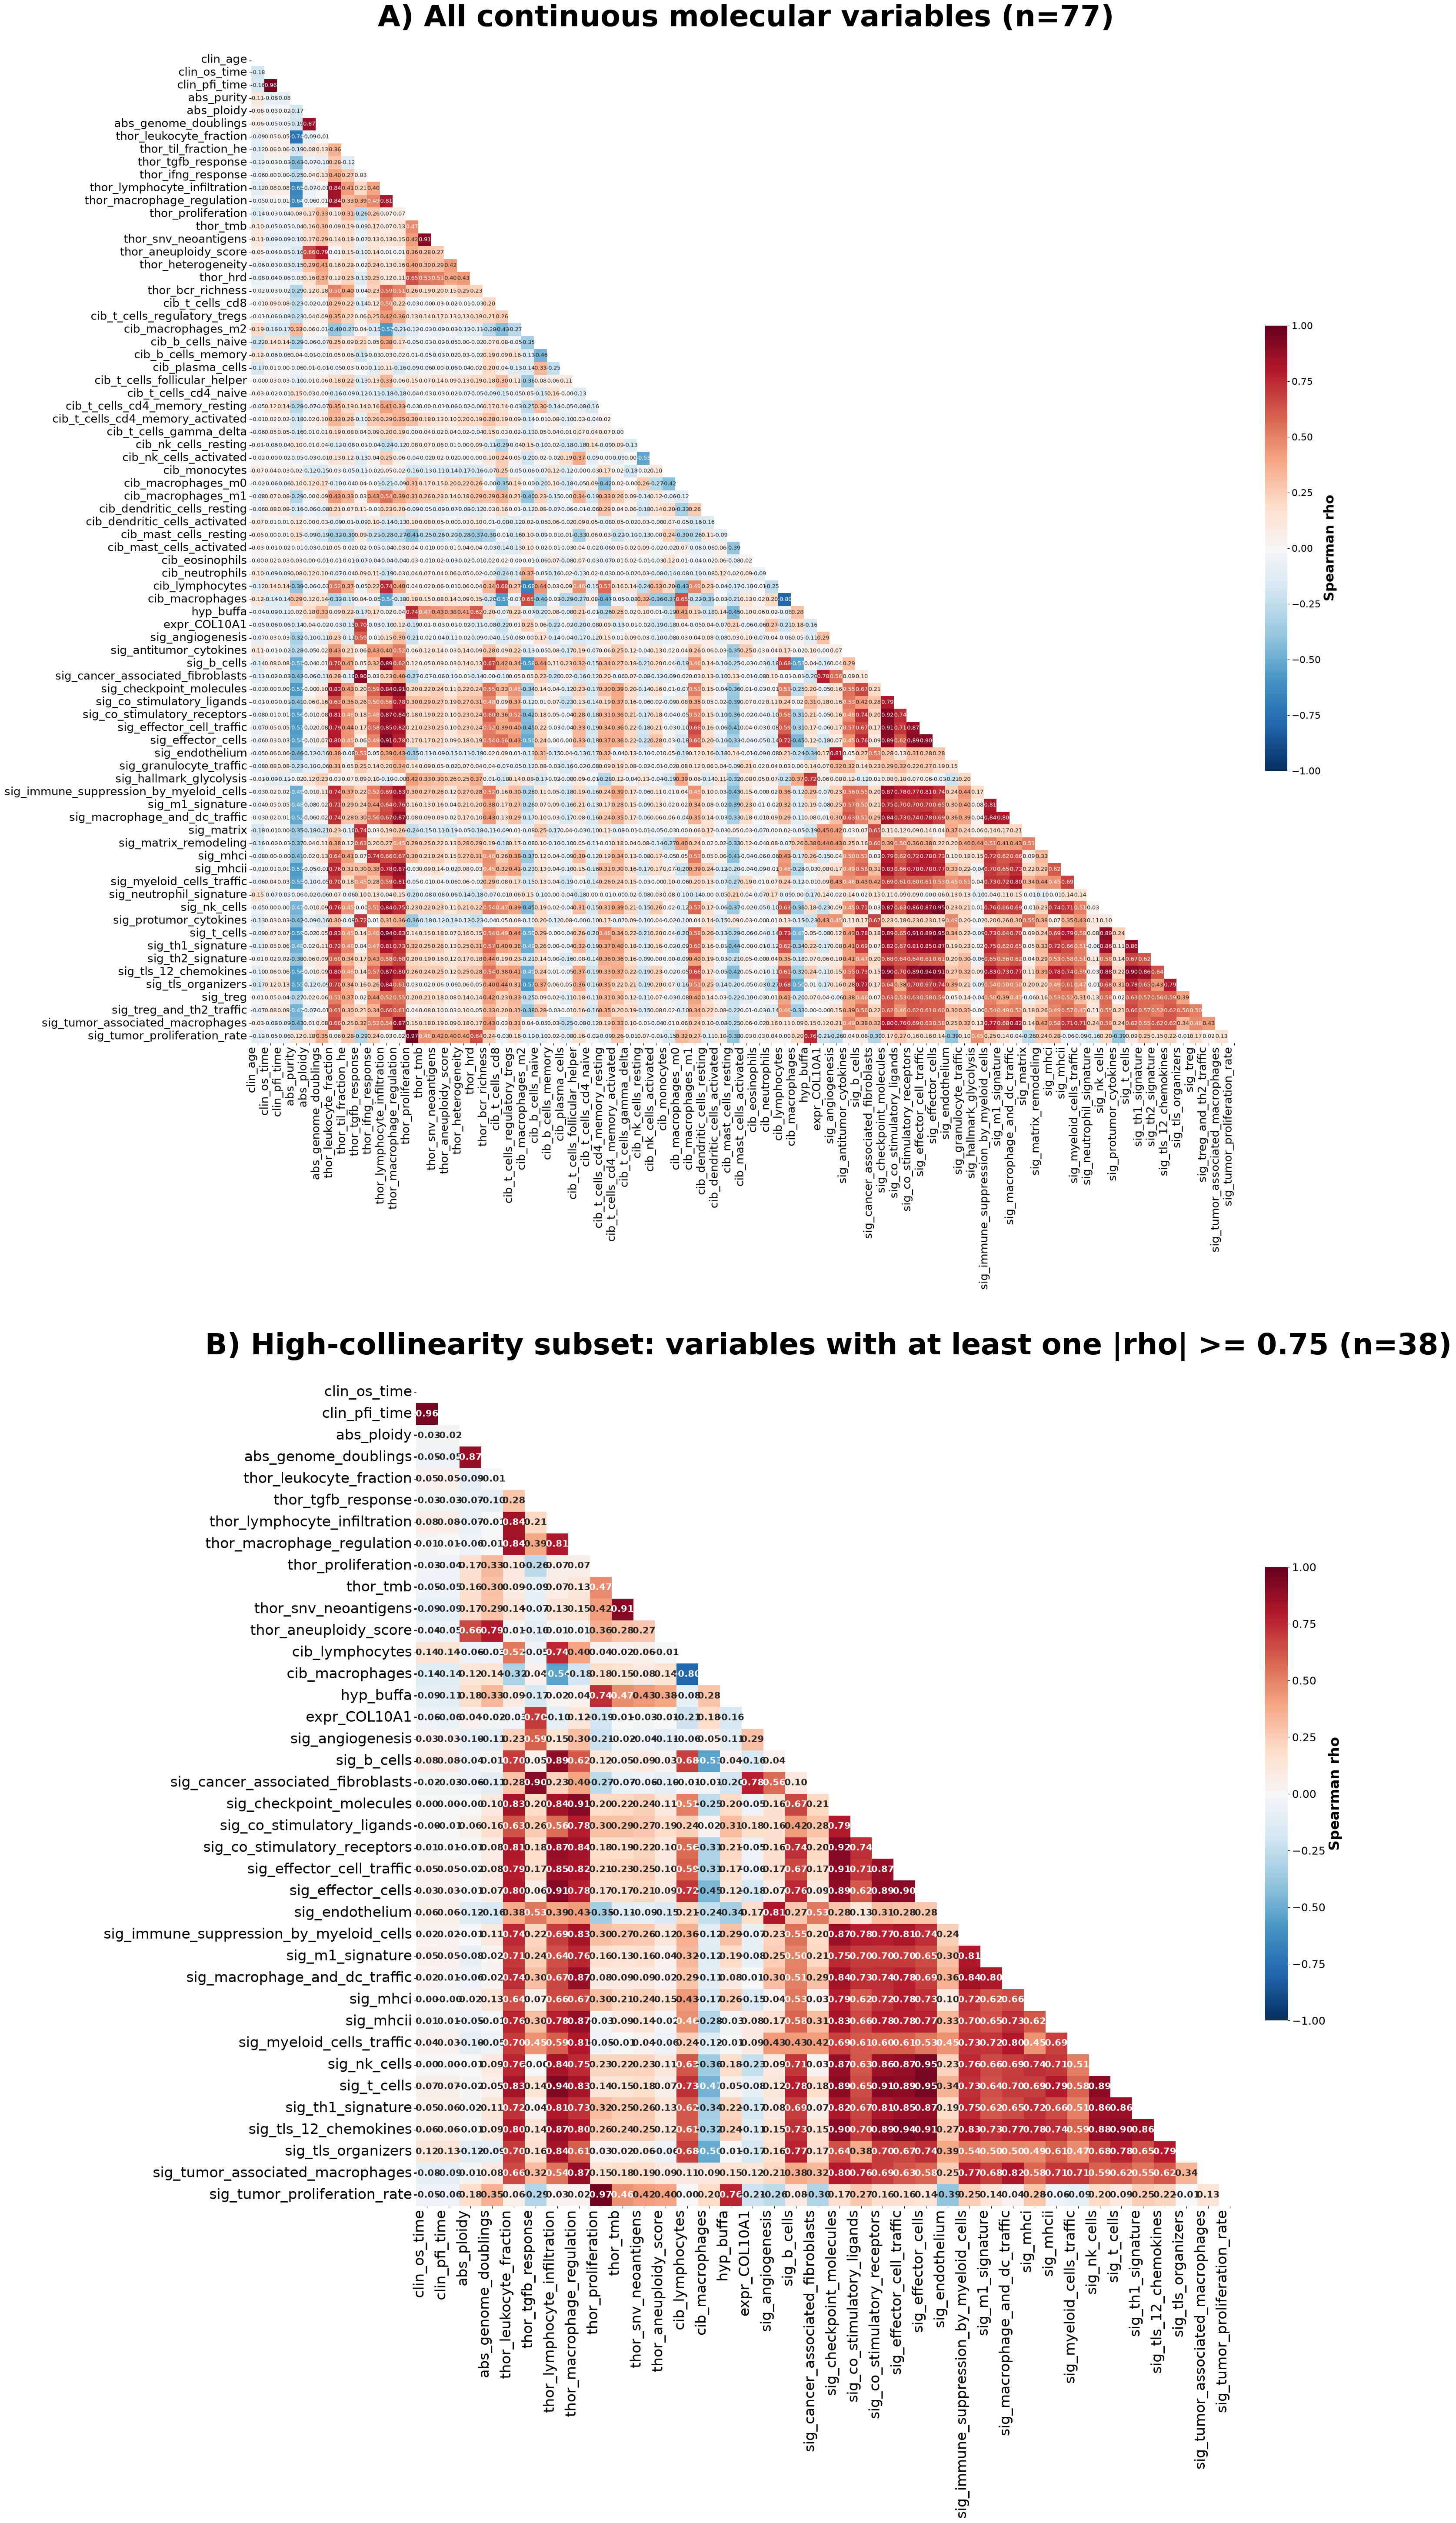

Panel B filtered from 77 down to 38 collinear variables.


In [38]:
# 1. Identify variables with at least one off-diagonal |rho| >= 0.75 (read-only safe)
collinear_vars = [c for c in corr.columns if (corr[c].abs() >= RHO_SCREENING).sum() > 1]
corr_high = corr.loc[collinear_vars, collinear_vars]

# 2. Upper triangle masks
mask_all = np.triu(np.ones_like(corr, dtype=bool))
mask_high = np.triu(np.ones_like(corr_high, dtype=bool))

# 3. Canvas setup: expanded size (34 x 58) with balanced height ratio
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(34, 58), gridspec_kw={"height_ratios": [1.2, 1.0]})

# Panel A: All continuous variables (full triangle)
hm1 = sns.heatmap(corr, mask=mask_all, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 9.5, "weight": "medium"}, square=True, cbar_kws={"shrink": 0.45, "label": "Spearman rho", "pad": 0.02}, ax=ax1)
ax1.set_title(f"A) All continuous molecular variables (n={len(corr)})", fontsize=48, fontweight="bold", pad=45)
ax1.tick_params(axis="both", which="major", labelsize=19)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=90, ha="right", fontsize=19)
ax1.set_yticklabels(ax1.get_yticklabels(), rotation=0, fontsize=19)
cbar1 = ax1.collections[0].colorbar
cbar1.ax.tick_params(labelsize=16); cbar1.set_label("Spearman rho", size=22, weight="bold")

# Panel B: High-collinearity subset (enlarged cells, labels and giant title)
hm2 = sns.heatmap(corr_high, mask=mask_high, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 15.0, "weight": "bold"}, square=True, cbar_kws={"shrink": 0.55, "label": "Spearman rho", "pad": 0.02}, ax=ax2)
ax2.set_title(f"B) High-collinearity subset: variables with at least one |rho| >= {RHO_SCREENING} (n={len(corr_high)})", fontsize=48, fontweight="bold", pad=45)
ax2.tick_params(axis="both", which="major", labelsize=24)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=90, ha="right", fontsize=24)
ax2.set_yticklabels(ax2.get_yticklabels(), rotation=0, fontsize=24)
cbar2 = ax2.collections[0].colorbar
cbar2.ax.tick_params(labelsize=18); cbar2.set_label("Spearman rho", size=24, weight="bold")

plt.tight_layout(h_pad=8.0)
plt.show()

print(f"Panel B filtered from {len(corr)} down to {len(corr_high)} collinear variables.")

**Observations (breast)**
- **One dominant immune axis:** leukocyte fraction, lymphocyte infiltration, macrophage regulation, CIBERSORT lymphocytes and almost all immune signatures (checkpoints, co-stimulation, effector, NK, T, Th1, TLS, MHC, myeloid) correlate at ρ ≈ 0.7–0.95. They largely measure how much immune infiltrate a tumour has: associations with them are not independent findings, and models need the redundancy filter and regularisation.
- **Other axes, nearly independent of the immune one (|ρ| < 0.3):** proliferation / hypoxia (proliferation scores ρ ≈ 0.97, Buffa hypoxia ≈ 0.75), chromosomal instability (ploidy, genome doublings, aneuploidy score), mutational burden (TMB, neoantigens), stroma / TGF-β (CAF, TGF-β response, COL10A1) and vasculature (endothelium, angiogenesis).
- **Two artefacts:** CIBERSORT lymphocytes vs macrophages (ρ ≈ −0.80) is compositional, since proportions within leukocytes sum to 1; OS vs PFI time (≈ 0.96) reflects shared follow-up in patients without events. Neither is biological redundancy.
- The pairs with |ρ| ≥ 0.90 are resolved below: one variable is dropped when both measure the same thing, and pairs that measure different biology are kept on purpose.

In [39]:
drop, redundancy_log = tcga.select_redundant(molecular, cont, RHO_REDUNDANT, RD.get("keep_pairs", []),
                                               RD.get("protected", []))
redundancy_log["rho"] = redundancy_log["rho"].round(2)
display(redundancy_log)
print(f"Dropped from the working table ({len(drop)}):")
for dropped, kept in drop.items():
    print(f"  {dropped:36s} represented by {kept}")

,var1,var2,rho,n_var1,n_var2,decision,reason
0,sig_tumor_proliferation_rate,thor_proliferation,0.97,1023,1013,drop thor_proliferation,sig_tumor_proliferation_rate pre-specified (pr...
1,clin_pfi_time,clin_os_time,0.96,1024,1024,kept,kept on purpose (keep_pairs)
2,sig_t_cells,sig_effector_cells,0.95,1023,1023,drop sig_t_cells,sig_effector_cells pre-specified (protected)
3,sig_nk_cells,sig_effector_cells,0.95,1023,1023,drop sig_nk_cells,sig_effector_cells pre-specified (protected)
4,sig_tls_12_chemokines,sig_effector_cell_traffic,0.94,1023,1023,drop sig_effector_cell_traffic,sig_tls_12_chemokines pre-specified (protected)
5,sig_t_cells,thor_lymphocyte_infiltration,0.94,1023,1013,resolved,sig_t_cells already dropped
6,sig_co_stimulatory_receptors,sig_checkpoint_molecules,0.92,1023,1023,drop sig_co_stimulatory_receptors,sig_checkpoint_molecules pre-specified (protec...
7,sig_effector_cells,thor_lymphocyte_infiltration,0.91,1023,1013,kept,kept on purpose (keep_pairs)
8,thor_snv_neoantigens,thor_tmb,0.91,932,995,drop thor_snv_neoantigens,thor_tmb pre-specified (protected)
9,sig_checkpoint_molecules,thor_macrophage_regulation,0.91,1023,1013,drop thor_macrophage_regulation,sig_checkpoint_molecules pre-specified (protec...


Dropped from the working table (7):
  thor_proliferation                   represented by sig_tumor_proliferation_rate
  sig_t_cells                          represented by sig_effector_cells
  sig_nk_cells                         represented by sig_effector_cells
  sig_effector_cell_traffic            represented by sig_tls_12_chemokines
  sig_co_stimulatory_receptors         represented by sig_checkpoint_molecules
  thor_snv_neoantigens                 represented by thor_tmb
  thor_macrophage_regulation           represented by sig_checkpoint_molecules


## 13. Save master table, working table and dictionary

- **Master:** all variables.
- **Working:** without the variables dropped in section 12 (input of notebook 03).
- **Dictionary:** one row per variable with source, level (main / secondary / exploratory), type, description, readable label (`configs/variable_labels.yaml`), coverage and redundancy.

In [40]:
with open(P["configs"] / "variable_labels.yaml") as fh:
    labels = yaml.safe_load(fh)["labels"]

dictionary = table.dictionary()
dictionary["label"] = dictionary["column"].map(lambda c: tcga.make_label(c, labels))
dictionary["in_working_table"] = ~dictionary["column"].isin(list(drop))
dictionary["redundant_with"] = dictionary["column"].map(drop)
no_label = dictionary.loc[dictionary["label"].isna(), "column"].tolist()
assert not no_label, f"Columns without a label (add them to configs/variable_labels.yaml): {no_label}"

master = table.data
working = master.drop(columns=list(drop))
assert master.index.is_unique
master.to_parquet(P["tcga_master"])
working.to_parquet(P["tcga_working"])
dictionary.to_csv(P["tcga_dictionary"], index=False)
print(f"Master: {master.shape} | Working: {working.shape} | Dictionary: {len(dictionary)} variables")

Master: (1025, 116) | Working: (1025, 109) | Dictionary: 116 variables


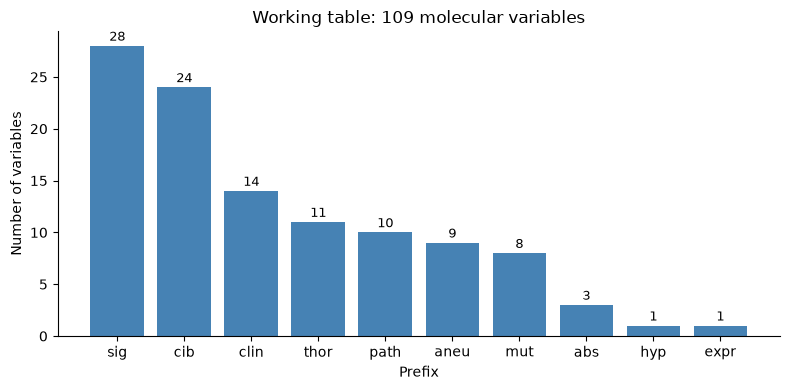

,prefix,column,source,level,type,label,pct_with_data
0,abs,abs_genome_doublings,ABSOLUTE (PanCanAtlas),main,continuous,Whole-genome doublings (ABSOLUTE),93.4
1,abs,abs_ploidy,ABSOLUTE (PanCanAtlas),main,continuous,Tumour ploidy (ABSOLUTE),93.4
2,abs,abs_purity,ABSOLUTE (PanCanAtlas),main,continuous,Tumour purity (ABSOLUTE),93.4
3,aneu,aneu_13q_loss,Taylor 2018 via cBioPortal,exploratory,binary,13q loss,80.4
4,aneu,aneu_16p_gain,Taylor 2018 via cBioPortal,exploratory,binary,16p gain,87.4
5,aneu,aneu_16q_loss,Taylor 2018 via cBioPortal,secondary,binary,16q loss,81.0
6,aneu,aneu_17p_loss,Taylor 2018 via cBioPortal,exploratory,binary,17p loss,85.4
7,aneu,aneu_1q_gain,Taylor 2018 via cBioPortal,exploratory,binary,1q gain,80.8
8,aneu,aneu_20q_gain,Taylor 2018 via cBioPortal,exploratory,binary,20q gain,83.6
9,aneu,aneu_22q_loss,Taylor 2018 via cBioPortal,exploratory,binary,22q loss,81.0


In [41]:
summary = dictionary[dictionary["in_working_table"]].assign(prefix=lambda d: d["column"].str.split("_").str[0])
counts = summary["prefix"].value_counts()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts.index, counts.values, color="steelblue")
for i, v in enumerate(counts.values):
    ax.text(i, v + 0.5, str(v), ha="center", fontsize=9)
ax.set(xlabel="Prefix", ylabel="Number of variables", title=f"Working table: {len(summary)} molecular variables")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIGS / "working_table_variables.png", dpi=150)
plt.show()

with pd.option_context("display.max_rows", None, "display.max_colwidth", 80):
    display(summary[["prefix", "column", "source", "level", "type", "label", "pct_with_data"]]
            .sort_values(["prefix", "column"]).reset_index(drop=True))